# CS771 Mini-Project 1: next-day PM2.5 forecasting for Bihar (Parts 1 to 5)

Please ensure that the four data files are available in `data/` (`bihar_pm25_hourly_jan_nov_2024.csv`, `bihar_stations.csv`, `bihar_grid_005deg.csv`, `bihar_boundary.csv`)

**Final model (used for Parts 3, 4 and 5).** A linear model on `log1p(PM2.5)`, fitted by least absolute deviations (Laplace likelihood, IRLS) on 25 features in 6 groups, and turned back into a mean forecast with a smearing factor. It was chosen on validation after comparing it with the ridge/lasso, tree, forest, boosting, k-NN, clustering and heteroscedastic models, all re-run below.

## Setup


In [1]:
import json, random, shutil, subprocess, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import norm
from sklearn.linear_model import Ridge, Lasso, LinearRegression, QuantileRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 0
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = Path("data")
OUT_DIR = Path("submission")          # Part 5 writes forecast.py, model.json and bihar_stations.csv here
N = 468                               # stations
for f in ["bihar_pm25_hourly_jan_nov_2024.csv", "bihar_stations.csv", "bihar_grid_005deg.csv", "bihar_boundary.csv"]:
    assert (DATA_DIR / f).exists(), f"missing data/{f}"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

### Helper functions
Everything the later parts share. Conventions: flat arrays are ordered issue time first, then station (column order of the data file); a row is train/validation by its **target** date; scores are in µg/m³ with forecasts clipped at 0.

In [2]:
def load_data(data_dir=DATA_DIR):
    # W: hourly PM2.5 (8040 hours x 468 stations); stations: lat/lon plus x_km, y_km from the spec's conversion
    data_dir = Path(data_dir)
    W = pd.read_csv(data_dir / "bihar_pm25_hourly_jan_nov_2024.csv", index_col="timestamp", parse_dates=True)
    W.columns = W.columns.astype(str)
    stations = pd.read_csv(data_dir / "bihar_stations.csv", dtype={"sensor_id": str}).set_index("sensor_id")
    stations["x_km"] = (stations.longitude - 85.5) * 100.3
    stations["y_km"] = (stations.latitude - 25.7) * 110.6
    assert list(stations.index) == list(W.columns) and W.shape == (8040, N) and not W.isna().any().any()
    return W, stations


def issue_times(lead=24, train_end="2024-08-31 12:00", val_end="2024-11-30 12:00"):
    # issue times = noon target times minus `lead` hours; train targets 3 Jan..train_end, validation targets 1 Sep..val_end
    make = lambda a, b: pd.date_range(a, b, freq="D") - pd.Timedelta(hours=lead)
    return make("2024-01-03 12:00", train_end), make("2024-09-01 12:00", val_end)


def targets(W, T, lead=24):
    return W.loc[pd.DatetimeIndex(T) + pd.Timedelta(hours=lead)].to_numpy().ravel()


def evaluate(pred, y, T, lead=24):
    # RMSE and MAE overall and per target month
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)
    assert pred.shape == y.shape and np.isfinite(pred).all(), "bad prediction array"
    err = pred - y
    out = {"RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err))}
    months = np.repeat((pd.DatetimeIndex(T) + pd.Timedelta(hours=lead)).month, N)
    for m in np.unique(months):
        e, name = err[months == m], pd.Timestamp(2024, m, 1).strftime("%b")
        out[f"RMSE {name}"], out[f"MAE {name}"] = np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e))
    return out


def lag_stack(W, T, hours=24):
    # L[i, s, k] = reading of station s at T[i] - k hours
    T = pd.DatetimeIndex(T)
    return np.stack([W.reindex(T - pd.Timedelta(hours=k)).to_numpy() for k in range(hours)], axis=2)


def neighbour_matrix(stations, k=10):
    # 468 x 468 matrix with 1/k on each station's k nearest OTHER stations (km); `readings @ A.T` = neighbour mean
    xy = stations[["x_km", "y_km"]].to_numpy()
    D = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(axis=2))
    np.fill_diagonal(D, np.inf)
    A = np.zeros((N, N))
    A[np.arange(N)[:, None], np.argsort(D, axis=1, kind="stable")[:, :k]] = 1.0 / k
    return A


def part1_features(W, T, A):
    # The 29 Part 1 features: 24 lags, neighbour mean now, neighbour mean over 24 h, network mean now, sin/cos of day
    T = pd.DatetimeIndex(T)
    L = lag_stack(W, T, 24)
    d = np.repeat((T.normalize() - pd.Timestamp("2024-01-01")).days.to_numpy(), N)
    X = np.column_stack([L.reshape(len(T) * N, 24),
                         (L[:, :, 0] @ A.T).ravel(),
                         np.einsum("tsk,js->tjk", L, A).mean(axis=2).ravel(),
                         np.repeat(L[:, :, 0].mean(axis=1), N),
                         np.sin(2 * np.pi * d / 365), np.cos(2 * np.pi * d / 365)])
    assert not np.isnan(X).any(), "need 24 h of history before every issue time"
    return X


def persistence(W, T):
    return W.loc[pd.DatetimeIndex(T)].to_numpy().ravel()


_RIDGE_CACHE = {}
def part1_ridge_predict(W, stations, T, lead=24):
    # Part 1 ridge (alpha=1, raw features), refitted for `lead` on the default training split
    if lead not in _RIDGE_CACHE:
        A = neighbour_matrix(stations)
        T_train, _ = issue_times(lead)
        _RIDGE_CACHE[lead] = Ridge(alpha=1.0).fit(part1_features(W, T_train, A), targets(W, T_train, lead))
    return np.clip(_RIDGE_CACHE[lead].predict(part1_features(W, T, neighbour_matrix(stations))), 0, None)


def compare(preds, W, stations, T, lead=24):
    # table of evaluate() for {name: forecast}, with persistence and Part 1 ridge on top
    y = targets(W, T, lead)
    rows = {"Persistence": evaluate(persistence(W, T), y, T, lead),
            "Ridge (Part 1)": evaluate(part1_ridge_predict(W, stations, T, lead), y, T, lead)}
    rows.update({name: evaluate(p, y, T, lead) for name, p in preds.items()})
    return pd.DataFrame(rows).T.round(2)

### Data, issue times and targets
Issue time = day d 12:00, target = day d+1 12:00. Ridge needs 24 h of history, so the first issue time is 2 Jan 12:00 (target 3 Jan). The asserts below check the split rules: the last training target is 31 Aug, the first validation target is 1 Sep.

In [3]:
W, stations = load_data()
T_train, T_val = issue_times()
y_train, y_val = targets(W, T_train), targets(W, T_val)

assert W.index.equals(pd.date_range("2024-01-01 00:00", "2024-11-30 23:00", freq="h"))
assert len(y_train) == 113_256 and len(y_val) == 42_588
assert (T_train + pd.Timedelta(hours=24)).max() <= pd.Timestamp("2024-08-31 12:00")
assert (T_val + pd.Timedelta(hours=24)).min() >= pd.Timestamp("2024-09-01 12:00")
assert not np.isnan(y_train).any() and not np.isnan(y_val).any()
print(W.shape, W.index.min(), "to", W.index.max())
print(f"Training:   {len(T_train)} issue days x {N} stations = {len(y_train):,} rows (issue {T_train[0]} to {T_train[-1]})")
print(f"Validation: {len(T_val)} issue days x {N} stations = {len(y_val):,} rows (issue {T_val[0]} to {T_val[-1]})")

(8040, 468) 2024-01-01 00:00:00 to 2024-11-30 23:00:00
Training:   242 issue days x 468 stations = 113,256 rows (issue 2024-01-02 12:00:00 to 2024-08-30 12:00:00)
Validation: 91 issue days x 468 stations = 42,588 rows (issue 2024-08-31 12:00:00 to 2024-11-29 12:00:00)


### Ten nearest neighbours and the 29 features
Distances in km with the spec's conversion; a station is never its own neighbour. Checks: (a) lag 0 equals the persistence forecast (row alignment); (b) one feature row recomputed by hand; (c) no leakage, i.e. features computed from history cut at t are identical.

In [4]:
A10 = neighbour_matrix(stations, 10)
assert np.allclose(A10.sum(axis=1), 1) and np.all(np.diag(A10) == 0)
D_km = np.sqrt(((stations[["x_km", "y_km"]].to_numpy()[:, None] - stations[["x_km", "y_km"]].to_numpy()[None]) ** 2).sum(axis=2))
np.fill_diagonal(D_km, np.inf)
srt = np.sort(D_km, axis=1)
print("Ties at the 10th neighbour:", int(np.isclose(srt[:, 9], srt[:, 10]).sum()))

X1_train, X1_val = part1_features(W, T_train, A10), part1_features(W, T_val, A10)
print("Part 1 feature matrices:", X1_train.shape, X1_val.shape)

pred_persist = persistence(W, T_val)
assert np.allclose(X1_val[:, 0], pred_persist)                                      # (a) alignment

t, s = pd.Timestamp("2024-03-15 12:00"), "100"                                      # (b) one row by hand
i, j = T_train.get_loc(t), list(W.columns).index(s)
nb = stations.index[np.argsort(D_km, axis=1, kind="stable")[j, :10]]
d = (t.normalize() - pd.Timestamp("2024-01-01")).days
expected = [W.loc[t, s], W.loc[t - pd.Timedelta(hours=23), s], W.loc[t, nb].mean(),
            W.loc[t - pd.Timedelta(hours=23):t, nb].to_numpy().mean(), W.loc[t].mean(),
            np.sin(2 * np.pi * d / 365), np.cos(2 * np.pi * d / 365)]
assert np.allclose(X1_train[i * N + j][[0, 23, 24, 25, 26, 27, 28]], expected)
assert y_train[i * N + j] == W.loc[t + pd.Timedelta(hours=24), s]
assert np.allclose(part1_features(W, [t], A10), part1_features(W.loc[:t], [t], A10))   # (c) leakage
print("Part 1 feature checks passed")

Ties at the 10th neighbour: 0


Part 1 feature matrices: (113256, 29) (42588, 29)


Part 1 feature checks passed


### Persistence and ridge, with the reference numbers
The reference values given for the project (persistence 32.75 / 17.47, ridge 29.58 / 18.16 RMSE / MAE) are asserted, so a mistake in the split or the features would stop the notebook here.

In [5]:
ridge1 = Ridge(alpha=1.0).fit(X1_train, y_train)
pred_ridge = np.clip(ridge1.predict(X1_val), 0, None)

REFERENCE = {"Persistence":    {"RMSE": 32.75, "MAE": 17.47, "RMSE Sep": 23.33, "MAE Sep": 8.91, "RMSE Oct": 20.22, "MAE Oct": 11.97, "RMSE Nov": 47.81, "MAE Nov": 31.70},
             "Ridge (Part 1)": {"RMSE": 29.58, "MAE": 18.16, "RMSE Sep": 20.34, "MAE Sep": 10.35, "RMSE Oct": 19.36, "MAE Oct": 13.46, "RMSE Nov": 43.06, "MAE Nov": 30.81}}
part1_table = compare({}, W, stations, T_val)
for name, ref in REFERENCE.items():
    for k, v in ref.items():
        assert abs(part1_table.loc[name, k] - v) < 0.01, f"{name} {k}: {part1_table.loc[name, k]} != {v}"
print("Part 1 reproduces the reference numbers")
display(part1_table)

for name, p in [("Persistence", pred_persist), ("Ridge", pred_ridge)]:
    e = p - y_val
    print(f"{name:12s} mean error {e.mean():+.2f}  median error {np.median(e):+.2f}  share |error| > 60: {np.mean(np.abs(e) > 60) * 100:.1f}%")
print(f"Validation targets: median {np.median(y_val):.1f}, mean {y_val.mean():.1f} ug/m3")

Part 1 reproduces the reference numbers


,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


Persistence  mean error -0.47  median error -0.75  share |error| > 60: 5.6%
Ridge        mean error +5.32  median error +7.20  share |error| > 60: 4.7%
Validation targets: median 32.3, mean 52.8 ug/m3


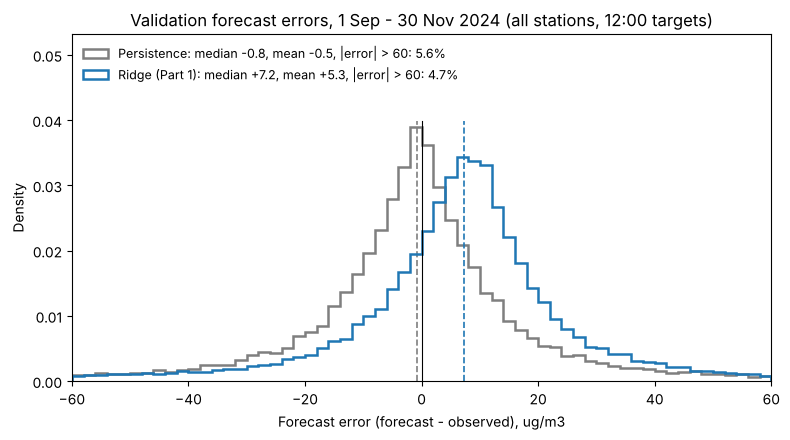

In [6]:
bins = np.arange(-60, 61, 2)
fig, ax = plt.subplots(figsize=(8, 4.5))
for err, name, color in [(pred_persist - y_val, "Persistence", "tab:gray"), (pred_ridge - y_val, "Ridge (Part 1)", "tab:blue")]:
    tail = np.mean(np.abs(err) > 60) * 100
    ax.hist(err, bins=bins, weights=np.full(err.shape, 1 / (len(err) * 2)), histtype="step", linewidth=1.8, color=color,
            label=f"{name}: median {np.median(err):+.1f}, mean {err.mean():+.1f}, |error| > 60: {tail:.1f}%")
    ax.axvline(np.median(err), color=color, linestyle="--", linewidth=1.2, ymax=0.75)
ax.axvline(0, color="black", linewidth=0.8, ymax=0.75)
ax.set_xlim(-60, 60); ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
ax.set_xlabel("Forecast error (forecast - observed), ug/m3"); ax.set_ylabel("Density")
ax.set_title("Validation forecast errors, 1 Sep - 30 Nov 2024 (all stations, 12:00 targets)")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

### Answer: RMSE vs MAE
Neither baseline wins on both metrics. Ridge has the lower RMSE (29.58 vs 32.75 µg/m³) but persistence has the lower MAE (17.47 vs 18.16); the MAE gap is largest in clean September (8.91 vs 10.35).

A model trained on squared error predicts the conditional mean, while absolute error is minimised by the conditional median. PM2.5 is right-skewed (validation targets: median 32.3, mean 52.8 µg/m³), so the mean sits above the median. Ridge accordingly over-predicts on a typical day (median error +7.2 µg/m³), which costs MAE because every day counts equally. In exchange it makes fewer large misses (4.7% of errors beyond ±60 µg/m³ vs 5.6% for persistence), and RMSE punishes large misses most. Persistence is almost unbiased (median error −0.8) and nearly exact on stable days, but it misses badly when pollution changes sharply.

**Decisions.** d = days since 1 Jan 2024 for the issue day, divisor 365 even though 2024 is a leap year. The network mean includes the station itself (all 468 stations). The 24 h neighbour mean averages all 240 readings (10 stations x 24 hours). There are no ties at the 10th neighbour. Training uses 113,256 rows: every station on every issue day from 2 Jan to 30 Aug (targets 3 Jan to 31 Aug).

## Part 2: Improving the forecast

Final model: **Laplace linear model on `log1p(PM2.5)` with a smeared-mean forecast**, using 25 features in 6 groups. The subsections *Features* to *Final model* build it, run the ablation and check it. The four subsections after that (*Ridge and lasso* to *Clustering stations*) re-run the other models on the same split, features and metric, and *All models side by side* compares everything.

PM2.5 is very skewed and changes by ratios (20 to 30 on a clean day, 200 to 300 on a smoggy day), so the model predicts `log1p(PM2.5)` instead of the raw value. If the errors are Laplace distributed, maximum likelihood means minimising the absolute error, and that gives the median, which is the best forecast for MAE. For RMSE the mean is better, so the forecast is scaled by a correction factor computed on the training data. The heteroscedastic variant also says how uncertain each forecast is.

### Protocol and training rows
- Fit on training rows (targets 3 Jan to 31 Aug); choose features and hyper-parameters on validation (targets 1 Sep to 30 Nov); score with `evaluate` in µg/m³ on **every station and every validation day** (nothing is dropped from validation).
- **Training rows used: 113,256** = 242 issue days x 468 stations. All days with 24 h of history are used (the lag features need 24 h; windows longer than the available history, such as the 7-day mean in the first days of January, are clipped at the start of the data). Nothing is dropped, because the training data is already small (242 distinct days) and, as the ablation shows, removing January (when pollution is highest) would remove the only winter-like days the model sees. For the final refit the same rule gives 155,844 rows (333 issue days, targets up to 30 Nov).
- Every scaler, climatology, smearing factor and cluster profile is fitted on training rows only.
- Group-ablation and feature selection use validation, so there is some selection on validation; the size of this effect is checked with rolling-origin folds inside the training period (*Final model* subsection) and with a block bootstrap.

### Features
Each feature uses only readings up to the issue time, and the pollution inputs are `log1p`-transformed.

| group | what it contains | columns |
|---|---|---|
| `own` | log readings at lags 0, 1, 2, 3, 6, 12, 18, 23 h, and mean, min, max, std of the last 24 h | 12 |
| `prevday` | log reading at t - 24 h | 1 |
| `nbr` | log mean of the 10 and 75 nearest stations (now and 24 h mean), and the station's difference from its 10 neighbours | 5 |
| `network` | log network mean now, its 24 h change, spread across stations | 3 |
| `trend` | 18 h change, last 6 h vs previous 6 h, last 24 h vs previous 24 h (log ratios) | 3 |
| `long` | log 7-day mean of the station | 1 |

Tried and dropped (see ablation): `clim` (station training mean, 4 columns), `long30` (30-day mean, 1 column), `calendar` (day of year, 2 columns).

In [7]:
SEL_LAGS = (0, 1, 2, 3, 6, 12, 18, 23)

def _row_index(W, T):
    index = W.index.get_indexer(pd.DatetimeIndex(T))
    assert (index >= 0).all(), "issue time not in history"
    return index

def _cumulative_sum(W):
    return np.vstack([np.zeros((1, W.shape[1])), np.cumsum(W.to_numpy(), axis=0)])

def _window_mean(cumulative, index, hours):
    # mean over hours index-hours+1 .. index, window clipped at the start of the data
    low = np.maximum(0, index - hours + 1)
    return (cumulative[index + 1] - cumulative[low]) / (index + 1 - low)[:, None]

def _repeat_for_stations(per_time_values):
    return np.repeat(per_time_values, N, axis=0)

def build_ctx_C(W, stations, train_end="2024-08-31 12:00"):
    # quantities fitted on TRAINING hours only (clim) plus the neighbour matrices
    train_hours = W.loc[:train_end]
    return dict(A10=neighbour_matrix(stations, k=10), A75=neighbour_matrix(stations, k=75),
                clim_mean=train_hours.mean().to_numpy(), clim_log_mean=np.log1p(train_hours).mean().to_numpy())

def g_own(W, T, ctx):
    log_lags = np.log1p(lag_stack(W, T, 24))
    picked = log_lags[:, :, list(SEL_LAGS)].reshape(-1, len(SEL_LAGS))
    summary = np.column_stack([log_lags.mean(axis=2).ravel(), log_lags.min(axis=2).ravel(),
                               log_lags.max(axis=2).ravel(), log_lags.std(axis=2).ravel()])
    names = [f"log_lag{k}" for k in SEL_LAGS] + ["log_mean24", "log_min24", "log_max24", "log_std24"]
    return np.column_stack([picked, summary]), names

def g_prevday(W, T, ctx):
    values, index = W.to_numpy(), _row_index(W, T)
    assert (index - 24 >= 0).all()
    return np.log1p(values[index - 24]).reshape(-1, 1), ["log_d1"]

def g_clim(W, T, ctx):
    values, index = W.to_numpy(), _row_index(W, T)
    cumulative = _cumulative_sum(W)
    log_clim = np.log1p(ctx["clim_mean"])[None, :]
    columns = [np.tile(log_clim, (len(index), 1)), np.tile(ctx["clim_log_mean"][None, :], (len(index), 1)),
               np.log1p(values[index]) - log_clim, np.log1p(_window_mean(cumulative, index, 24)) - log_clim]
    return np.stack(columns, axis=2).reshape(-1, 4), ["log_clim", "clim_log_mean", "anom_now", "anom_mean24"]

def g_nbr(W, T, ctx):
    values, index = W.to_numpy(), _row_index(W, T)
    cumulative = _cumulative_sum(W)
    now_nbr10 = values[index] @ ctx["A10"].T
    mean24 = _window_mean(cumulative, index, 24)
    columns = [np.log1p(now_nbr10), np.log1p(mean24 @ ctx["A10"].T), np.log1p(values[index] @ ctx["A75"].T),
               np.log1p(mean24 @ ctx["A75"].T), np.log1p(values[index]) - np.log1p(now_nbr10)]
    return (np.stack(columns, axis=2).reshape(-1, 5),
            ["log_nbr10_now", "log_nbr10_mean24", "log_nbr75_now", "log_nbr75_mean24", "local_anom"])

def g_network(W, T, ctx):
    values, index = W.to_numpy(), _row_index(W, T)
    log_now = np.log1p(values[index].mean(axis=1))
    log_change24 = log_now - np.log1p(values[index - 24].mean(axis=1))
    spread = np.log1p(values[index]).std(axis=1)
    return _repeat_for_stations(np.column_stack([log_now, log_change24, spread])), ["log_net_now", "log_net_chg24", "net_log_std"]

def g_trend(W, T, ctx):
    values, index = W.to_numpy(), _row_index(W, T)
    cumulative = _cumulative_sum(W)
    change18 = np.log1p(values[index]) - np.log1p(values[index - 17])
    last6 = _window_mean(cumulative, index, 6)
    previous6 = (cumulative[index - 5] - cumulative[np.maximum(0, index - 11)]) / (index - 5 - np.maximum(0, index - 11))[:, None]
    last24 = _window_mean(cumulative, index, 24)
    low, high = np.maximum(0, index - 47), index - 24
    previous24 = (cumulative[high + 1] - cumulative[low]) / (high + 1 - low)[:, None]
    columns = [change18, np.log1p(last6) - np.log1p(previous6), np.log1p(last24) - np.log1p(previous24)]
    return np.stack(columns, axis=2).reshape(-1, 3), ["log_chg18", "log_mom6", "log_chg_day"]

def g_long(W, T, ctx):
    index = _row_index(W, T)
    return np.log1p(_window_mean(_cumulative_sum(W), index, 168)).reshape(-1, 1), ["log_mean7d"]

def g_long30(W, T, ctx):
    index = _row_index(W, T)
    return np.log1p(_window_mean(_cumulative_sum(W), index, 720)).reshape(-1, 1), ["log_mean30d"]

def g_calendar(W, T, ctx):
    days = (pd.DatetimeIndex(T).normalize() - pd.Timestamp("2024-01-01")).days.to_numpy()
    angle = 2 * np.pi * days / 365
    return _repeat_for_stations(np.column_stack([np.sin(angle), np.cos(angle)])), ["sin_doy", "cos_doy"]

GROUPS = dict(own=g_own, prevday=g_prevday, clim=g_clim, nbr=g_nbr, network=g_network, trend=g_trend,
              long=g_long, long30=g_long30, calendar=g_calendar)
FINAL_GROUPS = ["own", "prevday", "nbr", "network", "trend", "long"]

def extract_features(W, T, ctx, groups=None):
    # returns (X, names, group_columns); rows ordered issue time first, then station
    groups = list(groups or FINAL_GROUPS)
    blocks, names, group_columns, start = [], [], {}, 0
    for group in groups:
        block, block_names = GROUPS[group](W, T, ctx)
        blocks.append(block); names += block_names
        group_columns[group] = list(range(start, start + block.shape[1])); start += block.shape[1]
    X = np.column_stack(blocks)
    assert X.shape[0] == len(T) * N and np.isfinite(X).all(), "bad feature matrix"
    return X, names, group_columns

### Feature tests: shape, NaN, leakage, parity
Shape and no NaN; **no leakage** (features for one issue time computed from the full series equal those computed from the history cut at that time); **parity** (a single-issue-time computation equals the corresponding rows of the batch matrix; this is what `forecast.py` relies on in Part 5).

In [8]:
ctx = build_ctx_C(W, stations)
X_train, feature_names, group_columns = extract_features(W, T_train, ctx, FINAL_GROUPS)
X_val, _, _ = extract_features(W, T_val, ctx, FINAL_GROUPS)

assert X_train.shape == (113_256, len(feature_names)) and X_val.shape == (42_588, len(feature_names))
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
for time_list, X_batch, position in [(T_val, X_val, 10), (T_train, X_train, 0), (T_train, X_train, 100)]:
    t = time_list[position]
    from_full_history, _, _ = extract_features(W, [t], ctx, FINAL_GROUPS)
    from_cut_history, _, _ = extract_features(W.loc[:t], [t], ctx, FINAL_GROUPS)
    assert np.allclose(from_full_history, from_cut_history), "leakage"
    assert np.allclose(from_full_history, X_batch[position * N:(position + 1) * N]), "parity"
print("shape, NaN, leakage and parity tests passed")
for group, columns in group_columns.items():
    print(f"{group:8s} ({len(columns):2d}):", [feature_names[c] for c in columns])
print("total features:", len(feature_names))

shape, NaN, leakage and parity tests passed
own      (12): ['log_lag0', 'log_lag1', 'log_lag2', 'log_lag3', 'log_lag6', 'log_lag12', 'log_lag18', 'log_lag23', 'log_mean24', 'log_min24', 'log_max24', 'log_std24']
prevday  ( 1): ['log_d1']
nbr      ( 5): ['log_nbr10_now', 'log_nbr10_mean24', 'log_nbr75_now', 'log_nbr75_mean24', 'local_anom']
network  ( 3): ['log_net_now', 'log_net_chg24', 'net_log_std']
trend    ( 3): ['log_chg18', 'log_mom6', 'log_chg_day']
long     ( 1): ['log_mean7d']
total features: 25


### Why log space
Three things in the training data suggest a log transform: the target is very skewed, the sensor stops at 500, and the level changes by more than 10 times between seasons, so ratios make more sense than differences.

skewness  raw: 2.38   log1p: 0.33
share of readings at the 500 cap: 0.003%


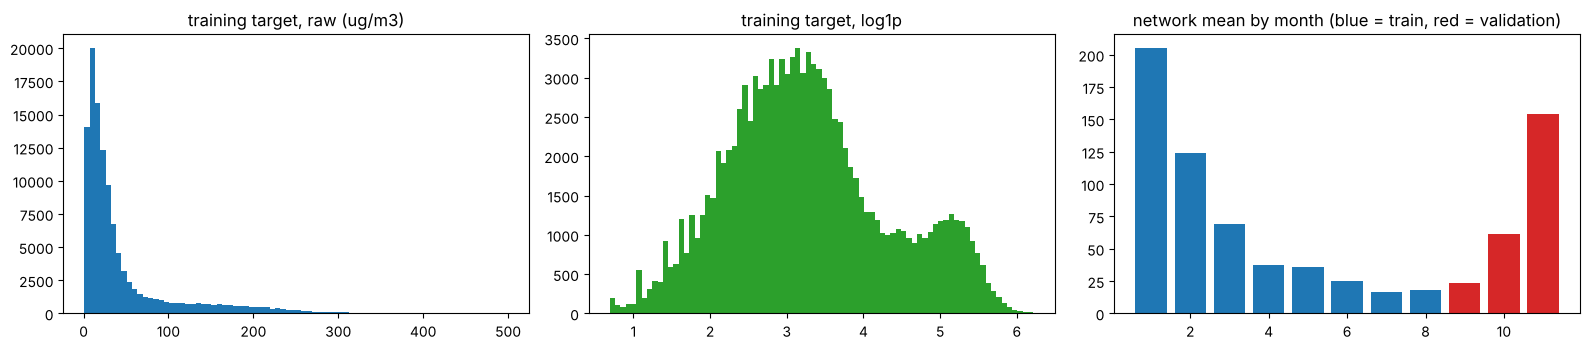

In [9]:
log_train, log_val = np.log1p(y_train), np.log1p(y_val)
print(f"skewness  raw: {pd.Series(y_train).skew():.2f}   log1p: {pd.Series(log_train).skew():.2f}")
print(f"share of readings at the 500 cap: {np.mean(W.to_numpy() >= 499.5):.3%}")

monthly_mean = W.mean(axis=1).groupby(W.index.month).mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].hist(y_train, bins=80, color="tab:blue"); axes[0].set_title("training target, raw (ug/m3)")
axes[1].hist(log_train, bins=80, color="tab:green"); axes[1].set_title("training target, log1p")
axes[2].bar(monthly_mean.index, monthly_mean.values, color=["tab:blue" if m <= 8 else "tab:red" for m in monthly_mean.index])
axes[2].set_title("network mean by month (blue = train, red = validation)")
plt.tight_layout(); plt.show()

Training has a falling season (January winter down to the July low) and validation has a rising one (September up to the November peak). This shift is the main problem in the project, and it is why November has the largest error for every model.

### Laplace linear model (IRLS)
Write `z = log1p(y) = w.x + b + noise`.
- Gaussian noise: maximum likelihood is least squares, and the best forecast is the mean.
- Laplace noise: maximum likelihood is the sum of absolute errors, and the best forecast is the median.

The absolute value is not differentiable at 0, so we use iteratively reweighted least squares (IRLS). Since |r| = r²/|r|, each step is a weighted least squares with weights 1/|r| from the previous residuals. It converges in about 20 steps. The code is written from scratch with numpy/scipy; first it is checked against scikit-learn's exact linear-programming solver on a subsample (the losses should match).

In [10]:
class Standardiser:
    # mean/std fitted on TRAINING rows only
    def fit(self, X):
        self.mean_ = X.mean(axis=0); self.scale_ = X.std(axis=0); self.scale_[self.scale_ == 0] = 1.0
        return self
    def transform(self, X):
        return (X - self.mean_) / self.scale_

def _with_intercept(X):
    return np.column_stack([np.ones(len(X)), X])


class LaplaceLinear:
    # least-absolute-deviation regression = MLE under Laplace noise, solved by IRLS with weights 1/max(|r|, eps)
    def __init__(self, l2=1e-3, max_iter=200, tol=1e-6, eps=1e-2):
        self.l2, self.max_iter, self.tol, self.eps = l2, max_iter, tol, eps

    def fit(self, X, y, sample_weight=None):
        self.scaler_ = Standardiser().fit(X)
        design = _with_intercept(self.scaler_.transform(X))
        base_weight = np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        penalty = self.l2 * np.eye(design.shape[1]); penalty[0, 0] = 0.0          # intercept unpenalised
        coefficients = np.linalg.solve(design.T @ (design * base_weight[:, None]) + penalty, design.T @ (base_weight * y))
        self.loss_history_ = []
        for _ in range(self.max_iter):
            residual = y - design @ coefficients
            self.loss_history_.append(np.mean(base_weight * np.abs(residual)))
            irls_weight = base_weight / np.maximum(np.abs(residual), self.eps)
            coefficients = np.linalg.solve(design.T @ (design * irls_weight[:, None]) + penalty, design.T @ (irls_weight * y))
            if len(self.loss_history_) > 1 and abs(self.loss_history_[-2] - self.loss_history_[-1]) < self.tol * self.loss_history_[-1]:
                break
        self.coef_ = coefficients
        self.scale_b_ = np.mean(np.abs(y - design @ coefficients))
        return self

    def predict(self, X):
        return _with_intercept(self.scaler_.transform(X)) @ self.coef_


class HeteroscedasticGaussian:
    # y ~ Normal(mu(x), sigma^2(x)), mu = w.x + b, log sigma^2 = v.x + c; maximum likelihood by L-BFGS with exact gradients
    def __init__(self, l2=1e-3, variance_columns=None, max_iter=500):
        self.l2, self.variance_columns, self.max_iter = l2, variance_columns, max_iter

    def fit(self, X, y, sample_weight=None):
        self.scaler_ = Standardiser().fit(X)
        scaled = self.scaler_.transform(X)
        mean_design = _with_intercept(scaled)
        columns = slice(None) if self.variance_columns is None else list(self.variance_columns)
        variance_design = _with_intercept(scaled[:, columns])
        n_mean, n_var = mean_design.shape[1], variance_design.shape[1]
        weight = np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        total_weight = weight.sum()
        start_mean = np.linalg.lstsq(mean_design, y, rcond=None)[0]
        start_variance = np.zeros(n_var); start_variance[0] = np.log(np.mean((y - mean_design @ start_mean) ** 2))
        start = np.concatenate([start_mean, start_variance])

        def objective(parameters):
            w, v = parameters[:n_mean], parameters[n_mean:]
            residual = y - mean_design @ w
            log_var = np.clip(variance_design @ v, -20, 20)
            inv_var = np.exp(-log_var)
            nll = 0.5 * np.sum(weight * (log_var + residual ** 2 * inv_var)) / total_weight
            grad_w = -(mean_design.T @ (weight * residual * inv_var)) / total_weight
            grad_v = 0.5 * (variance_design.T @ (weight * (1 - residual ** 2 * inv_var))) / total_weight
            nll += 0.5 * self.l2 * (np.sum(w[1:] ** 2) + np.sum(v[1:] ** 2)) / len(y)
            grad_w[1:] += self.l2 * w[1:] / len(y); grad_v[1:] += self.l2 * v[1:] / len(y)
            return nll, np.concatenate([grad_w, grad_v])

        result = minimize(objective, start, jac=True, method="L-BFGS-B", options=dict(maxiter=self.max_iter, maxfun=self.max_iter * 2))
        self.result_ = result
        self.mean_coef_, self.var_coef_ = result.x[:n_mean], result.x[n_mean:]
        self._columns = columns
        return self

    def predict_mean_and_variance(self, X):
        scaled = self.scaler_.transform(X)
        mu = _with_intercept(scaled) @ self.mean_coef_
        log_var = np.clip(_with_intercept(scaled[:, self._columns]) @ self.var_coef_, -20, 20)
        return mu, np.exp(log_var)

    def predict(self, X):
        return self.predict_mean_and_variance(X)[0]


MAX_PM25 = 500.0

class LogLaplaceForecaster:
    # Laplace linear model on log1p(PM2.5) -> forecasts in ug/m3.
    # mode="median": expm1(mu), the exact conditional median (MAE-optimal).
    # mode="mean":   exp(mu) * smearing - 1, smearing = mean(exp(train residual)) (Duan 1983), the RMSE-optimal forecast.
    def __init__(self, l2=1e-3, mode="mean"):
        self.l2, self.mode = l2, mode
    def fit(self, X, y_micrograms):
        log_target = np.log1p(y_micrograms)
        self.model_ = LaplaceLinear(l2=self.l2).fit(X, log_target)
        self.smearing_ = np.mean(np.exp(log_target - self.model_.predict(X)))
        return self
    def predict(self, X, mode=None):
        mu = self.model_.predict(X)
        forecast = np.expm1(mu) if (mode or self.mode) == "median" else np.exp(mu) * self.smearing_ - 1.0
        return np.clip(forecast, 0.0, MAX_PM25)


class LogHeteroGaussianForecaster:
    # heteroscedastic Gaussian on log1p(PM2.5); mean forecast = log-normal mean exp(mu + sigma^2/2) - 1
    def __init__(self, l2=1e-3, variance_columns=None):
        self.l2, self.variance_columns = l2, variance_columns
    def fit(self, X, y_micrograms):
        self.model_ = HeteroscedasticGaussian(l2=self.l2, variance_columns=self.variance_columns).fit(X, np.log1p(y_micrograms))
        return self
    def predict(self, X, mode="mean"):
        mu, variance = self.model_.predict_mean_and_variance(X)
        return np.clip(np.expm1(mu) if mode == "median" else np.expm1(mu + variance / 2.0), 0.0, MAX_PM25)
    def predict_log_distribution(self, X):
        mu, variance = self.model_.predict_mean_and_variance(X)
        return mu, np.sqrt(variance)

In [11]:
rng = np.random.default_rng(SEED)
subsample = rng.choice(len(y_train), 3000, replace=False)
standardised = (X_train[subsample] - X_train[subsample].mean(axis=0)) / X_train[subsample].std(axis=0)
mine = LaplaceLinear(l2=0.0).fit(X_train[subsample], log_train[subsample])
reference = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs").fit(standardised, log_train[subsample])
mean_absolute_error = lambda predicted: np.mean(np.abs(log_train[subsample] - predicted))
print(f"mean |error|   mine (IRLS): {mean_absolute_error(mine.predict(X_train[subsample])):.5f}   scikit-learn LP: {mean_absolute_error(reference.predict(standardised)):.5f}")

mean |error|   mine (IRLS): 0.36529   scikit-learn LP: 0.36528


### Level target vs log target
Same features, five set-ups. Forecasts are converted back to µg/m³ before scoring.

In [12]:
def summarise(name, forecast):
    scores = evaluate(forecast, y_val, T_val)
    return dict(model=name, RMSE=scores["RMSE"], MAE=scores["MAE"], RMSE_Nov=scores["RMSE Nov"],
                bias=np.mean(np.clip(forecast, 0, None) - y_val))

laplace = LogLaplaceForecaster().fit(X_train, y_train)
rows = [
    summarise("OLS, level target", LinearRegression().fit(X_train, y_train).predict(X_val)),
    summarise("Laplace (LAD), level target", LaplaceLinear().fit(X_train, y_train).predict(X_val)),
    summarise("OLS, log1p target, expm1", np.expm1(LinearRegression().fit(X_train, log_train).predict(X_val))),
    summarise("Laplace, log1p target, median", laplace.predict(X_val, mode="median")),
    summarise("Laplace, log1p target, smeared mean", laplace.predict(X_val, mode="mean")),
]
pd.DataFrame(rows).round(2)

,model,RMSE,MAE,RMSE_Nov,bias
0,"OLS, level target",34.70,22.96,49.33,6.18
1,"Laplace (LAD), level target",37.18,21.32,57.35,-4.58
2,"OLS, log1p target, expm1",30.68,16.76,45.96,-8.29
3,"Laplace, log1p target, median",29.27,16.02,43.28,-6.00
4,"Laplace, log1p target, smeared mean",28.16,15.74,41.05,-0.30


From this table:
1. Level targets are poor, because one additive formula has to cover values from 5 to 500.
2. In log space, absolute loss beats squared loss (OLS).
3. The median forecast has good MAE but is biased low, since the data is right-skewed (mean above median). For RMSE we multiply `exp(mu)` by the average of `exp(training residual)` (Duan smearing). For exactly Laplace errors the factor would be 1/(1 - s²), but the residuals are not exactly Laplace, so we use the empirical one. Both are printed below.

Laplace scale s = 0.371
if residuals were exactly Laplace: 1/(1-s^2) = 1.159
if residuals were Gaussian with the same mean |error|: 1.114
empirical smearing factor (training residuals): 1.119


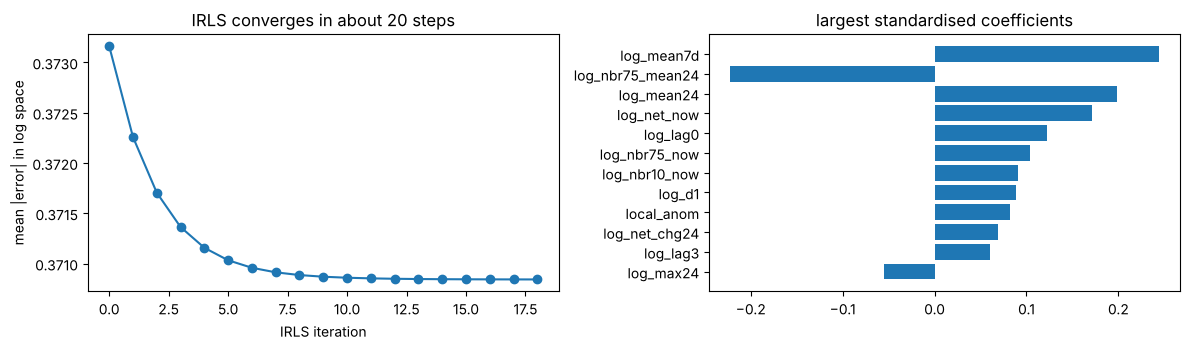

In [13]:
scale_s = laplace.model_.scale_b_
print(f"Laplace scale s = {scale_s:.3f}")
print(f"if residuals were exactly Laplace: 1/(1-s^2) = {1 / (1 - scale_s ** 2):.3f}")
print(f"if residuals were Gaussian with the same mean |error|: {np.exp((scale_s * np.sqrt(np.pi / 2)) ** 2 / 2):.3f}")
print(f"empirical smearing factor (training residuals): {laplace.smearing_:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(laplace.model_.loss_history_, marker="o")
axes[0].set_xlabel("IRLS iteration"); axes[0].set_ylabel("mean |error| in log space"); axes[0].set_title("IRLS converges in about 20 steps")
coefficients = pd.Series(laplace.model_.coef_[1:], index=feature_names).sort_values(key=np.abs, ascending=False).head(12)
axes[1].barh(coefficients.index[::-1], coefficients.values[::-1]); axes[1].set_title("largest standardised coefficients")
plt.tight_layout(); plt.show()

### Heteroscedastic Gaussian model
Here the mean and the variance both depend on the inputs (log link for the variance so it stays positive): `log1p(y) ~ Normal(mu(x), sigma²(x))`, with `mu = w.x + b` and `log sigma² = v.x + c`. It is fitted by maximum likelihood with L-BFGS and exact gradients (class above). Rows with a large predicted variance get less weight when fitting `w`. The forecast in µg/m³ is the log-normal mean, `exp(mu + sigma²/2) - 1`.

To check the uncertainty we look at how often the intervals contain the true value, the validation negative log-likelihood against a constant-variance model, and predicted vs actual spread for each month.

In [14]:
hetero = LogHeteroGaussianForecaster().fit(X_train, y_train)
mu_train, _ = hetero.predict_log_distribution(X_train)
mu_val, sigma_val = hetero.predict_log_distribution(X_val)
months_val = np.repeat((T_val + pd.Timedelta(hours=24)).month, N)

print("optimiser converged:", hetero.model_.result_.success, "| iterations:", hetero.model_.result_.nit)
coverage = {f"{int(level * 100)}%": round(float(np.mean(np.abs(log_val - mu_val) <= norm.ppf(0.5 + level / 2) * sigma_val)), 3) for level in (0.5, 0.8, 0.9)}
print("central interval coverage on validation (nominal -> actual):", coverage)
nll = lambda mu, sigma: np.mean(0.5 * np.log(2 * np.pi * sigma ** 2) + 0.5 * ((log_val - mu) / sigma) ** 2)
constant_sigma = np.sqrt(np.mean((log_train - mu_train) ** 2))
print(f"validation NLL (log space): heteroscedastic {nll(mu_val, sigma_val):.3f}   constant sigma {nll(mu_val, constant_sigma):.3f}")
pd.DataFrame({
    "mean predicted sigma": [sigma_val[months_val == m].mean() for m in (9, 10, 11)],
    "actual residual std": [np.std((log_val - mu_val)[months_val == m]) for m in (9, 10, 11)],
    "mean residual": [np.mean((log_val - mu_val)[months_val == m]) for m in (9, 10, 11)]}, index=["Sep", "Oct", "Nov"]).round(3)

optimiser converged: True | iterations: 239
central interval coverage on validation (nominal -> actual): {'50%': 0.548, '80%': 0.839, '90%': 0.917}
validation NLL (log space): heteroscedastic 0.629   constant sigma 0.683


,mean predicted sigma,actual residual std,mean residual
Sep,0.512,0.525,-0.020
Oct,0.439,0.457,0.032
Nov,0.457,0.435,0.109


The intervals are close to the nominal level (80% gives about 84%), the likelihood is better than with constant variance, and the predicted spread follows the real one. The mean residual in November is +0.11, so the model still under-predicts in the rising season.

### Ablation (required by the task)
**Feature groups and counts:** `own` 12, `prevday` 1, `nbr` 5, `network` 3, `trend` 3, `long` 1 = 25 features in 6 groups (listed in the *Feature tests* subsection).

Starting from the final model (Laplace on `log1p`, smeared-mean forecast, `l2 = 1e-3`), we refit **without one group at a time, with the same hyper-parameters**, and note the change in validation RMSE and MAE (positive means the group helped). Then we add the groups that are not in the final model one by one. The second table adds each group to `own` alone, because the groups overlap and drop-one understates their value (information that two groups share is "removed" only when both go).

In [15]:
ALL_GROUPS = list(GROUPS)
X_train_all, all_names, all_columns = extract_features(W, T_train, ctx, ALL_GROUPS)
X_val_all, _, _ = extract_features(W, T_val, ctx, ALL_GROUPS)
columns_of = lambda groups: [column for group in groups for column in all_columns[group]]

def fit_and_score(groups):
    columns = columns_of(groups)
    model = LogLaplaceForecaster().fit(X_train_all[:, columns], y_train)
    s = evaluate(model.predict(X_val_all[:, columns]), y_val, T_val)
    return dict(n_features=len(columns), RMSE=s["RMSE"], MAE=s["MAE"], RMSE_Sep=s["RMSE Sep"], RMSE_Oct=s["RMSE Oct"], RMSE_Nov=s["RMSE Nov"])

full_scores = fit_and_score(FINAL_GROUPS)
ablation = [dict(setting="final model (6 groups)", **full_scores, delta_RMSE=0.0, delta_MAE=0.0)]
for group in FINAL_GROUPS:
    s = fit_and_score([g for g in FINAL_GROUPS if g != group])
    ablation.append(dict(setting=f"- {group}", **s, delta_RMSE=s["RMSE"] - full_scores["RMSE"], delta_MAE=s["MAE"] - full_scores["MAE"]))
for group in ["clim", "long30", "calendar"]:
    s = fit_and_score(FINAL_GROUPS + [group])
    ablation.append(dict(setting=f"+ {group}", **s, delta_RMSE=s["RMSE"] - full_scores["RMSE"], delta_MAE=s["MAE"] - full_scores["MAE"]))
s = fit_and_score(["own", "prevday", "clim", "nbr", "network", "trend"])
ablation.append(dict(setting="first draft (with clim, no long)", **s, delta_RMSE=s["RMSE"] - full_scores["RMSE"], delta_MAE=s["MAE"] - full_scores["MAE"]))
ablation_table = pd.DataFrame(ablation).set_index("setting")
display(ablation_table.round(2))

additive_rows = []
for extra in [None, "prevday", "nbr", "network", "trend", "long"]:
    additive_rows.append(dict(setting="own alone" if extra is None else f"own + {extra}", **fit_and_score(["own"] if extra is None else ["own", extra])))
additive_table = pd.DataFrame(additive_rows).set_index("setting")
additive_table["RMSE_gain_vs_own"] = additive_table.loc["own alone", "RMSE"] - additive_table["RMSE"]
additive_table["MAE_gain_vs_own"] = additive_table.loc["own alone", "MAE"] - additive_table["MAE"]
display(additive_table.round(2))

,n_features,RMSE,MAE,RMSE_Sep,RMSE_Oct,RMSE_Nov,delta_RMSE,delta_MAE
setting,,,,,,,,
final model (6 groups),25,28.16,15.74,20.05,17.57,41.05,0.00,0.00
- own,13,28.24,15.77,19.84,17.50,41.34,0.08,0.03
- prevday,24,28.16,15.74,20.15,17.56,41.00,0.00,-0.01
- nbr,20,28.42,15.96,20.24,17.97,41.31,0.25,0.22
- network,22,28.98,16.18,20.08,17.95,42.56,0.82,0.44
- trend,22,28.15,15.74,20.06,17.58,41.02,-0.01,-0.01
- long,24,28.37,16.18,20.23,18.18,41.11,0.21,0.44
+ clim,29,28.28,15.77,20.47,17.71,41.02,0.12,0.03
+ long30,26,28.47,15.62,20.13,17.10,41.86,0.31,-0.12


,n_features,RMSE,MAE,RMSE_Sep,RMSE_Oct,RMSE_Nov,RMSE_gain_vs_own,MAE_gain_vs_own
setting,,,,,,,,
own alone,12,29.93,17.20,20.51,19.30,43.73,0.00,0.00
own + prevday,13,29.91,17.19,20.39,19.27,43.75,0.02,0.01
own + nbr,17,29.43,16.74,20.46,18.50,43.07,0.50,0.46
own + network,15,28.87,16.60,20.67,18.76,41.67,1.06,0.60
own + trend,15,29.79,17.14,20.41,19.25,43.49,0.14,0.06
own + long,13,29.45,16.58,20.23,18.58,43.18,0.48,0.62


**Overlap between `prevday` and `trend`.** Each of them alone changes nothing when removed (0.00 and −0.01 RMSE), which could just mean they cover for each other. The check below drops **both together** (21 features).

In [16]:
both_dropped = fit_and_score([g for g in FINAL_GROUPS if g not in ("prevday", "trend")])
print(f"final (25 features):               RMSE {full_scores['RMSE']:.3f}  MAE {full_scores['MAE']:.3f}")
print(f"without prevday AND trend (21):    RMSE {both_dropped['RMSE']:.3f}  MAE {both_dropped['MAE']:.3f}")

final (25 features):               RMSE 28.162  MAE 15.743
without prevday AND trend (21):    RMSE 28.159  MAE 15.722


Validation is only 91 days and neighbouring days are related, so differences of 0.1 to 0.3 RMSE are within noise. As a second check we use rolling-origin validation **inside the training period** (train on early months, test on the next ones), which does not use the validation set. `clim` is left out there because its training mean would include the test months.

In [17]:
target_times_train = (T_train + pd.Timedelta(hours=24)).repeat(N)
folds = {"train <= Mar, test Apr-May": ("2024-03-31 23:59", "2024-04-01", "2024-05-31 23:59"),
         "train <= May, test Jun-Jul": ("2024-05-31 23:59", "2024-06-01", "2024-07-31 23:59"),
         "train <= Jun, test Jul-Aug": ("2024-06-30 23:59", "2024-07-01", "2024-08-31 23:59")}
candidates = {"final (6 groups)": FINAL_GROUPS, "final - long": [g for g in FINAL_GROUPS if g != "long"],
              "final + long30": FINAL_GROUPS + ["long30"], "final + calendar": FINAL_GROUPS + ["calendar"]}
lag0_column = all_names.index("log_lag0")
rolling_rows = []
for fold_name, (train_end, test_start, test_end) in folds.items():
    in_train = target_times_train <= pd.Timestamp(train_end)
    in_test = (target_times_train >= pd.Timestamp(test_start)) & (target_times_train <= pd.Timestamp(test_end))
    persistence_forecast = np.expm1(X_train_all[in_test, lag0_column])
    rolling_rows.append(dict(fold=fold_name, model="persistence", RMSE=np.sqrt(np.mean((persistence_forecast - y_train[in_test]) ** 2)),
                             MAE=np.mean(np.abs(persistence_forecast - y_train[in_test]))))
    for name, groups in candidates.items():
        columns = columns_of(groups)
        forecast = LogLaplaceForecaster().fit(X_train_all[in_train][:, columns], y_train[in_train]).predict(X_train_all[in_test][:, columns])
        rolling_rows.append(dict(fold=fold_name, model=name, RMSE=np.sqrt(np.mean((forecast - y_train[in_test]) ** 2)),
                                 MAE=np.mean(np.abs(forecast - y_train[in_test]))))
rolling = pd.DataFrame(rolling_rows)
for metric in ("RMSE", "MAE"):
    print(metric); display(rolling.pivot(index="model", columns="fold", values=metric)[list(folds)].round(2))

RMSE


fold,"train <= Mar, test Apr-May","train <= May, test Jun-Jul","train <= Jun, test Jul-Aug"
model,,,
final (6 groups),19.12,17.05,17.45
final + calendar,18.95,16.95,18.08
final + long30,19.19,17.06,17.48
final - long,19.28,16.85,17.40
persistence,23.15,20.37,21.25


MAE


fold,"train <= Mar, test Apr-May","train <= May, test Jun-Jul","train <= Jun, test Jul-Aug"
model,,,
final (6 groups),8.47,7.81,7.61
final + calendar,8.66,8.54,9.53
final + long30,8.43,7.78,7.56
final - long,9.07,7.83,7.75
persistence,9.87,8.76,8.88


### Final model: comparison with the baselines, and is the gain real?
`compare` shows persistence and the Part 1 ridge on top. Training RMSE is added to see the train-vs-validation gap. A paired block bootstrap over validation days (7-day blocks, since neighbouring days are correlated) gives a 95% interval for RMSE(final) − RMSE(other); if the whole interval is below 0, the final model is better.

In [18]:
final_predictions = {
    "Laplace median (MAE-optimal)": laplace.predict(X_val, mode="median"),
    "Laplace smeared mean (FINAL)": laplace.predict(X_val, mode="mean"),
    "Heteroscedastic Gaussian": hetero.predict(X_val),
}
train_predictions = {"Laplace median (MAE-optimal)": laplace.predict(X_train, mode="median"),
                     "Laplace smeared mean (FINAL)": laplace.predict(X_train, mode="mean"),
                     "Heteroscedastic Gaussian": hetero.predict(X_train)}
comparison = compare(final_predictions, W, stations, T_val)
comparison["Train RMSE"] = [np.nan, np.nan] + [round(float(np.sqrt(np.mean((train_predictions[n] - y_train) ** 2))), 2) for n in final_predictions]
display(comparison)

def daily_squared_error(forecast):
    return ((np.clip(forecast, 0, None) - y_val) ** 2).reshape(len(T_val), N).mean(axis=1)

def block_bootstrap_interval(squared_error_a, squared_error_b, block=7, n_boot=2000, seed=SEED):
    generator = np.random.default_rng(seed)
    n_days = len(squared_error_a); n_blocks = int(np.ceil(n_days / block)); differences = []
    for _ in range(n_boot):
        starts = generator.integers(0, n_days - block + 1, n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n_days]
        differences.append(np.sqrt(squared_error_a[idx].mean()) - np.sqrt(squared_error_b[idx].mean()))
    return np.percentile(differences, [2.5, 50, 97.5]).round(2)

final_pred_val = final_predictions["Laplace smeared mean (FINAL)"]
final_squared_error = daily_squared_error(final_pred_val)
others = {"Persistence": persistence(W, T_val), "Ridge (Part 1)": part1_ridge_predict(W, stations, T_val),
          "Laplace median": final_predictions["Laplace median (MAE-optimal)"],
          "Heteroscedastic Gaussian": final_predictions["Heteroscedastic Gaussian"]}
print("delta RMSE = RMSE(final) - RMSE(other), 95% block-bootstrap interval [2.5%, 50%, 97.5%]")
for name, forecast in others.items():
    print(f"  vs {name:28s}", block_bootstrap_interval(final_squared_error, daily_squared_error(forecast)))

,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov,Train RMSE
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70,NaN
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81,NaN
Laplace median (MAE-optimal),29.27,16.02,20.22,7.49,17.49,10.62,43.28,30.13,28.05
Laplace smeared mean (FINAL),28.16,15.74,20.05,7.88,17.57,10.95,41.05,28.56,28.01
Heteroscedastic Gaussian,28.69,16.05,20.01,8.00,17.38,10.84,42.24,29.50,27.68


delta RMSE = RMSE(final) - RMSE(other), 95% block-bootstrap interval [2.5%, 50%, 97.5%]
  vs Persistence                  [-5.56 -3.84 -2.37]
  vs Ridge (Part 1)               [-1.9  -0.83 -0.27]
  vs Laplace median            [-2.51 -1.35 -0.23]
  vs Heteroscedastic Gaussian  [-1.28 -0.62  0.01]


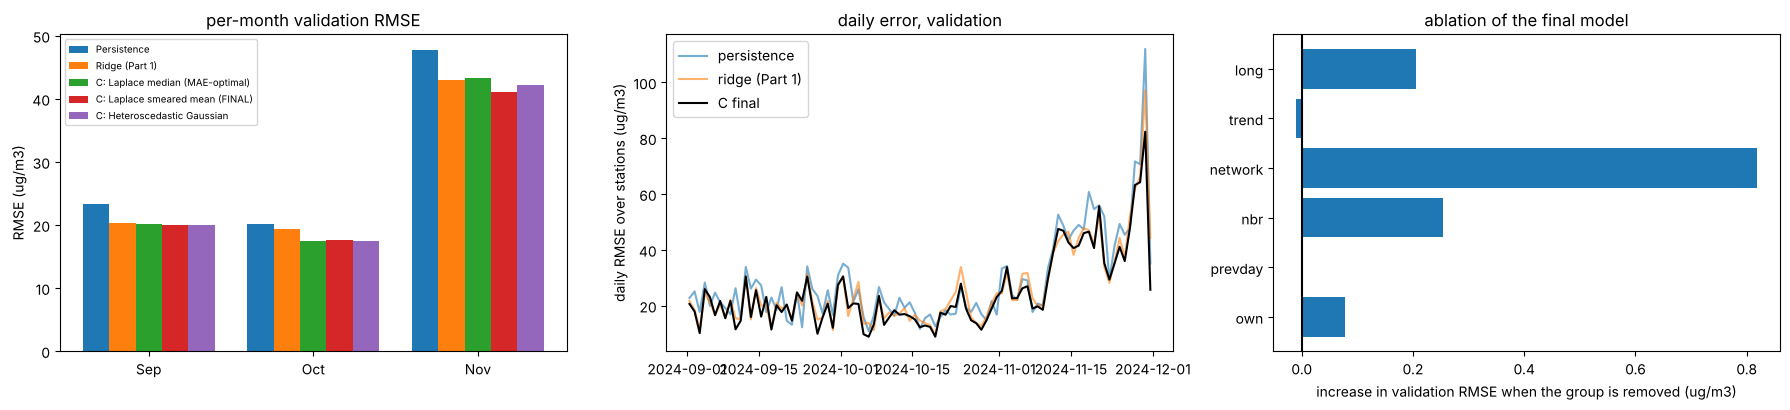

In [19]:
dates = T_val + pd.Timedelta(hours=24)
persistence_error = np.sqrt(daily_squared_error(persistence(W, T_val)))
ridge_error = np.sqrt(daily_squared_error(others["Ridge (Part 1)"]))
final_error = np.sqrt(final_squared_error)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
months = ["RMSE Sep", "RMSE Oct", "RMSE Nov"]
plotted = ["Persistence", "Ridge (Part 1)", "Laplace median (MAE-optimal)", "Laplace smeared mean (FINAL)", "Heteroscedastic Gaussian"]
for position, name in enumerate(plotted):
    axes[0].bar(np.arange(3) + 0.16 * position, comparison.loc[name, months].values, 0.16, label=name)
axes[0].set_xticks(np.arange(3) + 0.32); axes[0].set_xticklabels(["Sep", "Oct", "Nov"])
axes[0].set_ylabel("RMSE (ug/m3)"); axes[0].set_title("per-month validation RMSE"); axes[0].legend(fontsize=7)
axes[1].plot(dates, persistence_error, alpha=0.6, label="persistence"); axes[1].plot(dates, ridge_error, alpha=0.6, label="ridge (Part 1)")
axes[1].plot(dates, final_error, color="k", label="C final")
axes[1].set_ylabel("daily RMSE over stations (ug/m3)"); axes[1].set_title("daily error, validation"); axes[1].legend()
drops = ablation_table.loc[[f"- {g}" for g in FINAL_GROUPS], "delta_RMSE"]
axes[2].barh([n[2:] for n in drops.index], drops.values); axes[2].axvline(0, color="k")
axes[2].set_xlabel("increase in validation RMSE when the group is removed (ug/m3)"); axes[2].set_title("ablation of the final model")
plt.tight_layout(); plt.show()

### Ridge and lasso
*The next four subsections try further models on the same split, features and metric.*
**Idea.** Keep the Part 1 ridge but improve what it sees. Questions: does regularisation matter, which target is better (level, change from persistence, log), which feature groups earn their place for a linear level model, and does a sparse (lasso) model keep the same groups?

All fits are on the 113,256 training rows (the group-add tables start at 8 Jan, so that 7 previous days exist for every group). Scalers are fitted on training rows only.

In [20]:
def rmse_clipped(p, y):
    return np.sqrt(np.mean((np.clip(p, 0, None) - y) ** 2))

lag0_tr, lag0_va = X1_train[:, 0], X1_val[:, 0]          # y(t): column 0 of the 29 Part 1 features
months_va = np.repeat((T_val + pd.Timedelta(hours=24)).month, N)

# --- (a) alpha sweep, standardised ridge on the 29 Part 1 features, level target
rows = []
for a in [0.01, 1, 100, 1e3, 1e4, 1e5, 1e6]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X1_train, y_train)
    pt, pv = m.predict(X1_train), m.predict(X1_val)
    ev = evaluate(pv, y_val, T_val)
    rows.append(dict(alpha=a, train_rmse=rmse_clipped(pt, y_train), val_rmse=ev["RMSE"], val_mae=ev["MAE"], rmse_nov=ev["RMSE Nov"],
                     val_bias=np.mean(np.clip(pv, 0, None) - y_val)))
display(pd.DataFrame(rows).round(3))

,alpha,train_rmse,val_rmse,val_mae,rmse_nov,val_bias
0,0.01,27.998,29.584,18.156,43.057,5.318
1,1.00,27.998,29.584,18.156,43.057,5.319
2,100.00,27.998,29.595,18.181,43.058,5.390
3,1000.00,28.011,29.700,18.379,43.102,5.906
4,10000.00,28.250,30.369,19.188,43.828,7.306
5,100000.00,29.208,31.444,19.839,45.428,6.168
6,1000000.00,33.710,33.575,21.226,49.462,0.625


The alpha sweep is a null result for the level target. Validation RMSE is flat at 29.584 up to alpha ≈ 10 and then rises monotonically. There is no interior optimum, so standardised ridge is effectively OLS here: 113k rows against 29 features leaves nothing for the penalty to fix. Gains will not come from regularisation.

The train/validation gap is small (28.0 vs 29.6), so this is not overfitting. The real problem is the +5.3 validation bias from distribution shift. It only crosses zero around alpha ≈ 1e6, where the model has degraded to the training mean (RMSE 33.6). So the next suspects are the sin/cos columns and the intercept, which encode Jan to Aug seasonality that does not carry over to Sep to Nov. That makes the target comparison and the no-sin/cos test the most informative next steps.

In [21]:
def fit_targets(Xtr, Xva, alpha):
    # one standardised-ridge fit per target, everything converted back to ug/m3; scaler and smearing factor use TRAIN rows only
    out = {}
    def fit(z):
        m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xtr, z)
        return m.predict(Xtr), m.predict(Xva)
    a, b = fit(y_train);              out["level"] = (a, b)
    a, b = fit(y_train - lag0_tr);    out["change"] = (a + lag0_tr, b + lag0_va)
    z = np.log1p(y_train); a, b = fit(z)
    clipz = lambda v: np.clip(v, 0, 7)
    out["log"] = (np.expm1(clipz(a)), np.expm1(clipz(b)))
    S = np.mean(np.exp(z - a))
    out["log_smear"] = (np.exp(clipz(a)) * S - 1, np.exp(clipz(b)) * S - 1)
    return out

rows = []
for feats, (Xa, Xb) in {"part1_29": (X1_train, X1_val), "part1_29 minus sin/cos": (X1_train[:, :27], X1_val[:, :27])}.items():
    for al in [1.0, 1e3, 1e5]:
        for tgt, (pt, pv) in fit_targets(Xa, Xb, al).items():
            ev = evaluate(pv, y_val, T_val)
            rows.append(dict(features=feats, target=tgt, alpha=al, train_rmse=rmse_clipped(pt, y_train), val_rmse=ev["RMSE"], val_mae=ev["MAE"],
                             sep=ev["RMSE Sep"], oct=ev["RMSE Oct"], nov=ev["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_val)))
display(pd.DataFrame(rows).round(2))
for nm, (Xa, Xb) in {"with sin/cos": (X1_train, X1_val), "no sin/cos": (X1_train[:, :27], X1_val[:, :27])}.items():
    e = np.clip(fit_targets(Xa, Xb, 1.0)["level"][1], 0, None) - y_val
    print(nm, "mean error by month:", {m: round(float(e[months_va == m].mean()), 2) for m in (9, 10, 11)})

,features,target,alpha,train_rmse,val_rmse,val_mae,sep,oct,nov,bias
0,part1_29,level,1.0,28.00,29.58,18.16,20.34,19.36,43.06,5.32
1,part1_29,change,1.0,28.00,29.58,18.16,20.34,19.36,43.06,5.32
2,part1_29,log,1.0,42.97,40.86,23.22,20.68,24.61,63.32,-14.81
3,part1_29,log_smear,1.0,52.17,41.36,21.41,20.13,21.93,65.47,-7.40
4,part1_29,level,1000.0,28.01,29.70,18.38,20.44,19.68,43.10,5.91
5,part1_29,change,1000.0,28.05,29.63,18.34,20.45,19.65,42.96,5.95
6,part1_29,log,1000.0,42.74,40.68,23.09,20.70,24.53,63.01,-14.41
7,part1_29,log_smear,1000.0,51.81,41.41,21.37,20.15,21.86,65.59,-6.93
8,part1_29,level,100000.0,29.21,31.44,19.84,20.95,21.92,45.43,6.17
9,part1_29,change,100000.0,31.36,31.34,17.11,22.51,19.49,45.61,0.65


with sin/cos mean error by month: {9: 5.55, 10: 6.86, 11: 3.49}


no sin/cos mean error by month: {9: 0.01, 10: -0.09, 11: -1.44}


**What this shows.** (1) The log targets are much worse for plain ridge (RMSE 40 to 48) because a squared-error fit in log space predicts the median and under-predicts the mean (the smeared version fixes the bias but not the damage in November); the level and change targets are identical at small alpha, since persistence is a column of the features. (2) Dropping the two sin/cos columns removes the validation bias (+5.3 → −0.5), cuts MAE from 18.16 to 16.69 and RMSE from 29.58 to 29.16: the calendar columns are fitted on a falling season (Jan to Aug) and pull the Sep to Nov forecasts upward. The mean error by month confirms this (+5.6, +6.9, +3.5 with sin/cos; ≈ 0 without). This is the same effect that makes the `calendar` group hurt the Laplace model in the *Ablation* subsection.

Next, a richer feature set for the linear level model, in groups so each can be switched on and off. The groups are: `own` (24 raw lags), `prevday` (the same hour on the previous 7 days), `trend` (24 h mean minus the previous 24 h mean), `long` (7-day, 30-day and training station mean), `nbr` (10-nearest now and 24 h mean, and means within 10, 25 and 50 km), `network` (mean, 24 h change, std), `calendar` (day-of-week of the target) and `transform` (log of lag 0, of the 10-neighbour mean and of the network mean).

In [22]:
def _p_i(W, T):
    i = W.index.get_indexer(pd.DatetimeIndex(T)); assert (i >= 0).all(); return i

def build_ctx_B(W, stations, train_end="2024-08-31 12:00"):
    xy = stations[["x_km", "y_km"]].to_numpy()
    D = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(2)); np.fill_diagonal(D, np.inf)
    R = []
    for r in (10, 25, 50):
        M = (D <= r).astype(float); e = M.sum(1) == 0
        M[e, D[e].argmin(1)] = 1.0; R.append(M / M.sum(1, keepdims=True))
    return dict(A10=neighbour_matrix(stations), R=R, st_mean=W.loc[:train_end].mean().to_numpy())

def pb_own(W, T, c):
    return lag_stack(W, T, 24).reshape(-1, 24), [f"lag{k}" for k in range(24)]
def pb_prevday(W, T, c):
    Wv, i = W.to_numpy(), _p_i(W, T); assert (i - 168 >= 0).all()
    return np.stack([Wv[i - 24 * k] for k in range(1, 8)], axis=2).reshape(-1, 7), [f"d{k}" for k in range(1, 8)]
def pb_trend(W, T, c):
    cs, i = _cumulative_sum(W), _p_i(W, T)
    cur = _window_mean(cs, i, 24); lo, hi = np.maximum(0, i - 47), i - 24
    prev = (cs[hi + 1] - cs[lo]) / (hi + 1 - lo)[:, None]
    return (cur - prev).reshape(-1, 1), ["trend24"]
def pb_long(W, T, c):
    cs, i = _cumulative_sum(W), _p_i(W, T)
    X = np.stack([_window_mean(cs, i, 168), _window_mean(cs, i, 720), np.tile(c["st_mean"], (len(i), 1))], axis=2)
    return X.reshape(-1, 3), ["mean7d", "mean30d", "train_mean"]
def pb_nbr(W, T, c):
    cs, i = _cumulative_sum(W), _p_i(W, T); Wv = W.to_numpy()
    cols = [Wv[i] @ c["A10"].T, _window_mean(cs, i, 24) @ c["A10"].T] + [Wv[i] @ M.T for M in c["R"]]
    return np.stack(cols, axis=2).reshape(-1, 5), ["nbr10_now", "nbr10_mean24", "nbr_r10", "nbr_r25", "nbr_r50"]
def pb_network(W, T, c):
    Wv, i = W.to_numpy(), _p_i(W, T)
    now = Wv[i].mean(1); chg = now - Wv[i - 24].mean(1); sd = Wv[i].std(1)
    return _repeat_for_stations(np.column_stack([now, chg, sd])), ["net_now", "net_chg24", "net_std"]
def pb_calendar(W, T, c):
    dow = (pd.DatetimeIndex(T) + pd.Timedelta(hours=24)).dayofweek.to_numpy()
    return _repeat_for_stations(np.eye(7)[dow][:, 1:]), [f"dow{k}" for k in range(1, 7)]
def pb_transform(W, T, c):
    Wv, i = W.to_numpy(), _p_i(W, T)
    cols = [np.log1p(Wv[i]), np.log1p(Wv[i] @ c["A10"].T), np.log1p(np.repeat(Wv[i].mean(1)[:, None], N, 1))]
    return np.stack(cols, axis=2).reshape(-1, 3), ["log_lag0", "log_nbr10", "log_net"]
GROUPS_B = dict(own=pb_own, prevday=pb_prevday, trend=pb_trend, long=pb_long, nbr=pb_nbr, network=pb_network, calendar=pb_calendar, transform=pb_transform)

ctxB = build_ctx_B(W, stations)
mask_T = T_train >= pd.Timestamp("2024-01-08 12:00")          # 7 days of history for every group
T_trm = T_train[mask_T]; rm = np.repeat(mask_T, N)
y_trm, lag0_trm = y_train[rm], X1_train[rm, 0]
blk_tr = {g: f(W, T_trm, ctxB) for g, f in GROUPS_B.items()}
blk_va = {g: f(W, T_val, ctxB) for g, f in GROUPS_B.items()}
blk_tr_full = {g: GROUPS_B[g](W, T_train, ctxB) for g in ["own", "network", "trend", "nbr"]}

for g, f in GROUPS_B.items():                                 # leakage + parity per group
    for T_, blk, j in [(T_val, blk_va, 10), (T_trm, blk_tr, 5)]:
        t = T_[j]; a = f(W, [t], ctxB)[0]
        assert np.allclose(a, f(W.loc[:t], [t], ctxB)[0]), f"LEAK in {g}"
        assert np.allclose(a, blk[g][0][j * N:(j + 1) * N]), f"PARITY in {g}"
print("leakage + parity OK:", {g: blk_tr[g][0].shape[1] for g in blk_tr})

def run_groups(groups, alpha=1.0):
    Xa = np.hstack([blk_tr[g][0] for g in groups]); Xb = np.hstack([blk_va[g][0] for g in groups])
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xa, y_trm)
    pt, pv = m.predict(Xa), m.predict(Xb); ev = evaluate(pv, y_val, T_val)
    return dict(groups="+".join(groups), n_feat=Xa.shape[1], train_rmse=rmse_clipped(pt, y_trm), val_rmse=ev["RMSE"], val_mae=ev["MAE"],
                sep=ev["RMSE Sep"], oct=ev["RMSE Oct"], nov=ev["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_val))

ALL_B = list(GROUPS_B)
res = [run_groups(["own"])] + [run_groups(["own", g]) for g in ALL_B if g != "own"] + [run_groups(ALL_B)]
tab = pd.DataFrame(res); tab["d_val_rmse"] = tab.val_rmse - tab.val_rmse.iloc[0]
tab.round(2)

leakage + parity OK: {'own': 24, 'prevday': 7, 'trend': 1, 'long': 3, 'nbr': 5, 'network': 3, 'calendar': 6, 'transform': 3}


,groups,n_feat,train_rmse,val_rmse,val_mae,sep,oct,nov,bias,d_val_rmse
0,own,24,27.79,29.86,17.29,19.69,19.30,43.96,0.58,0.00
1,own+prevday,31,27.22,29.89,17.16,19.47,18.88,44.29,-1.17,0.02
2,own+trend,25,27.72,29.82,17.30,19.62,19.36,43.88,0.55,-0.04
3,own+long,27,27.47,29.81,16.97,19.57,18.59,44.22,-3.84,-0.05
4,own+nbr,29,27.50,29.44,16.96,19.71,18.57,43.41,-0.20,-0.42
5,own+network,27,27.21,29.04,16.73,19.71,18.53,42.59,-0.13,-0.83
6,own+calendar,30,27.74,29.93,17.29,19.71,19.18,44.15,0.58,0.07
7,own+transform,27,27.58,29.61,17.37,19.81,19.17,43.45,1.19,-0.25
8,own+prevday+trend+long+nbr+network+calendar+tr...,52,26.25,30.31,17.03,19.59,18.32,45.34,-7.38,0.44


Adding groups one at a time to `own` (the table above) shows that `network` (−0.83 RMSE) and `nbr` (−0.42) help most, `transform` helps somewhat, and `prevday`, `trend`, `long` and `calendar` do nothing individually. Using **all** groups is worse (30.31, bias −7.4 in the table) than `own` alone. The next cell finds out which part of the full model hurts, by dropping one group at a time from the full model, and then selects groups greedily.

In [23]:
feat_tr = {n: blk_tr[g][0][:, j] for g in blk_tr for j, n in enumerate(blk_tr[g][1])}
feat_va = {n: blk_va[g][0][:, j] for g in blk_va for j, n in enumerate(blk_va[g][1])}

def run_feats(names, alpha=1.0):
    Xa = np.column_stack([feat_tr[n] for n in names]); Xb = np.column_stack([feat_va[n] for n in names])
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xa, y_trm)
    pt, pv = m.predict(Xa), m.predict(Xb); ev = evaluate(pv, y_val, T_val)
    return dict(n_feat=Xa.shape[1], train=rmse_clipped(pt, y_trm), val=ev["RMSE"], mae=ev["MAE"], sep=ev["RMSE Sep"], oct=ev["RMSE Oct"],
                nov=ev["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_val))

gnames = lambda gs: [n for g in gs for n in blk_tr[g][1]]
full = run_feats(gnames(ALL_B))
rows = [dict(removed="(none)", **full, d_val=0.0)]
for g in ALL_B:
    r = run_feats(gnames([x for x in ALL_B if x != g])); rows.append(dict(removed=g, **r, d_val=r["val"] - full["val"]))
display(pd.DataFrame(rows).round(2))

sel, best = ["own"], run_feats(gnames(["own"]))["val"]            # greedy forward selection over groups (selected on validation: optimistic)
while True:
    cand = [(run_feats(gnames(sel + [g]))["val"], g) for g in ALL_B if g not in sel]
    if not cand: break
    v, g = min(cand)
    if best - v < 0.05: break
    sel.append(g); best = v; print("add", g, round(v, 3))
print("selected:", sel)

,removed,n_feat,train,val,mae,sep,oct,nov,bias,d_val
0,(none),52,26.25,30.31,17.03,19.59,18.32,45.34,-7.38,0.00
1,own,28,26.98,32.04,18.06,20.48,19.41,48.01,-8.61,1.73
2,prevday,45,26.54,29.70,16.73,19.66,18.38,44.05,-6.71,-0.61
3,trend,51,26.26,30.35,17.04,19.60,18.33,45.41,-7.39,0.04
4,long,49,26.42,29.07,16.32,19.42,17.84,43.09,-2.94,-1.24
5,nbr,47,26.32,30.20,17.01,19.66,18.36,45.07,-6.88,-0.11
6,network,49,26.66,30.58,17.37,19.72,18.39,45.81,-6.28,0.27
7,calendar,46,26.31,30.27,17.04,19.56,18.38,45.24,-7.31,-0.04
8,transform,49,26.30,29.96,16.78,19.66,17.81,44.81,-6.14,-0.35


add network 29.036


add trend 28.865


add nbr 28.773


selected: ['own', 'network', 'trend', 'nbr']


Removing `long` from the full model improves it most (−1.24) and also removes most of the bias (−7.4 → −2.9). The `mean30d` column is the cause: in the rising Sep to Nov season a 30-day mean lags behind and pulls forecasts down. (The Laplace model's feature set uses only a 7-day mean, and the same group was a gain there.) Greedy forward selection picks `own, network, trend, nbr`: the final set for this model (33 features). It uses validation, so the result is optimistic; the rolling-origin check in the *Ablation* subsection was done for the Laplace model's feature set.

Final ridge model: groups `own + network + trend + nbr` on all 113,256 training rows, alpha = 100 (the difference between alpha = 1 and 100 is below 0.01 RMSE).

In [24]:
SEL = ["own", "network", "trend", "nbr"]
def fit_eval(groups, alpha=100, target="level"):
    Xa = np.hstack([blk_tr_full[g][0] for g in groups]); Xb = np.hstack([blk_va[g][0] for g in groups])
    otr, ova = (X1_train[:, 0], X1_val[:, 0]) if target == "change" else (0, 0)
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xa, y_train - otr)
    pt, pv = m.predict(Xa) + otr, m.predict(Xb) + ova; ev = evaluate(pv, y_val, T_val)
    return dict(n_feat=Xa.shape[1], train=rmse_clipped(pt, y_train), val=ev["RMSE"], mae=ev["MAE"], sep=ev["RMSE Sep"], oct=ev["RMSE Oct"],
                nov=ev["RMSE Nov"], bias=np.mean(np.clip(pv, 0, None) - y_val)), m, pv

rows = []
for tgt in ["level", "change"]:
    for a in [1, 100, 1e3, 1e4]:
        r, _, _ = fit_eval(SEL, a, tgt); rows.append(dict(target=tgt, alpha=a, **r))
display(pd.DataFrame(rows).round(2))

full_r, m_full, ridge_final_pred = fit_eval(SEL, 100, "level")
rows = [dict(removed="(none)", n_removed=0, **full_r, d_val=0.0)]
for g in SEL:                                                       # drop-one from the final ridge model
    r, _, _ = fit_eval([x for x in SEL if x != g], 100)
    rows.append(dict(removed=g, n_removed=blk_tr_full[g][0].shape[1], **r, d_val=r["val"] - full_r["val"]))
display(pd.DataFrame(rows).round(2))

names_B = [n for g in SEL for n in blk_tr_full[g][1]]
coef = pd.Series(m_full[-1].coef_, index=names_B)
print("largest standardised coefficients (ug/m3 per 1 sd):"); print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).round(2).to_string())

,target,alpha,n_feat,train,val,mae,sep,oct,nov,bias
0,level,1.0,33,27.87,28.71,16.43,19.51,18.16,42.18,-0.53
1,level,100.0,33,27.87,28.71,16.43,19.51,18.16,42.17,-0.48
2,level,1000.0,33,27.89,28.73,16.48,19.55,18.23,42.16,-0.15
3,level,10000.0,33,28.11,29.08,16.87,19.78,18.60,42.61,0.75
4,change,1.0,33,27.87,28.71,16.43,19.51,18.15,42.17,-0.53
5,change,100.0,33,27.87,28.69,16.42,19.51,18.15,42.15,-0.48
6,change,1000.0,33,27.93,28.65,16.42,19.52,18.15,42.05,-0.19
7,change,10000.0,33,28.90,29.21,16.53,20.40,18.53,42.63,0.14


,removed,n_removed,n_feat,train,val,mae,sep,oct,nov,bias,d_val
0,(none),0,33,27.87,28.71,16.43,19.51,18.16,42.17,-0.48,0.00
1,own,24,9,33.87,36.34,21.10,23.18,21.77,54.58,-1.33,7.63
2,network,3,30,28.43,29.35,16.94,19.64,18.65,43.21,0.08,0.64
3,trend,1,32,27.97,28.88,16.49,19.58,18.16,42.50,-0.57,0.17
4,nbr,5,28,28.04,28.81,16.65,19.64,18.52,42.17,0.31,0.11


largest standardised coefficients (ug/m3 per 1 sd):
net_now         20.75
lag0            13.78
nbr10_mean24   -10.98
lag1             5.79
nbr10_now        4.59
lag2             4.40
lag18            4.08
lag23            3.60


In [25]:
Xa = np.hstack([blk_tr_full[g][0] for g in SEL]); Xb = np.hstack([blk_va[g][0] for g in SEL])
sc = StandardScaler().fit(Xa); Za, Zb = sc.transform(Xa), sc.transform(Xb)
rows = []
for tgt in ["level", "change"]:
    otr, ova = (X1_train[:, 0], X1_val[:, 0]) if tgt == "change" else (0, 0)
    for a in [1e-3, 1e-2, 0.1, 0.3, 1, 3]:
        ls = Lasso(alpha=a, max_iter=50000, random_state=SEED).fit(Za, y_train - otr)
        pt, pv = ls.predict(Za) + otr, ls.predict(Zb) + ova
        e = evaluate(pv, y_val, T_val); nz = ls.coef_ != 0
        rows.append(dict(target=tgt, alpha=a, nnz=int(nz.sum()), train=rmse_clipped(pt, y_train), val=e["RMSE"], mae=e["MAE"], nov=e["RMSE Nov"],
                         bias=np.mean(np.clip(pv, 0, None) - y_val), **{g: int(sum(nz[i] for i, n in enumerate(names_B) if n in blk_tr_full[g][1])) for g in SEL}))
pd.DataFrame(rows).round(2)

,target,alpha,nnz,train,val,mae,nov,bias,own,network,trend,nbr
0,level,0.00,33,27.87,28.71,16.43,42.17,-0.52,24,3,1,5
1,level,0.01,33,27.87,28.70,16.43,42.17,-0.49,24,3,1,5
2,level,0.10,23,27.90,28.72,16.47,42.18,-0.16,17,3,1,2
3,level,0.30,20,28.00,28.83,16.63,42.30,0.41,16,2,1,1
4,level,1.00,17,28.18,29.02,16.81,42.61,0.51,14,2,1,0
5,level,3.00,15,28.51,29.32,17.09,43.14,0.15,14,1,0,0
6,change,0.00,33,27.87,28.71,16.43,42.17,-0.52,24,3,1,5
7,change,0.01,33,27.87,28.70,16.43,42.16,-0.49,24,3,1,5
8,change,0.10,23,27.91,28.67,16.44,42.12,-0.19,17,3,1,2
9,change,0.30,20,28.09,28.75,16.55,42.18,0.31,15,2,1,2


**Ridge/lasso conclusions.** The final ridge model (`own + network + trend + nbr`, 33 features, raw level target) gets validation RMSE 28.71 / MAE 16.43, beating Part 1 ridge (29.58 / 18.16) in every month; the gain comes from leaving out the sin/cos columns (which carried the seasonal bias) and from adding `network` and `nbr` information. Dropping `own` costs +7.6 RMSE (it is the core), `network` +0.64, `trend` +0.17 and `nbr` +0.11 (the neighbour group is partly covered by the network and trend groups). Lasso with a small penalty gives the same score; larger penalties zero out `nbr` and `trend` first and then lose accuracy, so the sparse model keeps `own` and `network`, consistent with the ablation. The change-from-persistence target is within noise of the level target. Its remaining weakness is that it is a *level* model: one additive formula for clean and smoggy days, which the log-space Laplace model of the *Level target vs log target* subsection handles better (28.16 / 15.74).

### Decision tree, random forest and gradient boosting
**Models (lecture 4):** a single regression tree, a random forest (bagged deep trees, lowers variance) and histogram gradient boosting (shallow trees added one after another, lowers bias).

**Features:** the same 25 features in 6 groups as the final model, so the only difference from the linear model is the model itself. The inputs are log-transformed, which does not matter for trees (a split only depends on the order of values).

**Protocol:** fit on training rows, choose everything on validation, score in µg/m³. Gradient boosting uses `early_stopping=False` because its built-in early stopping holds out a *random* 10% of rows, which mixes days across time (that would break the rule "never shuffle rows into a random split"; the number of iterations is chosen on the validation curve instead).

In [26]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

p_train, p_val = persistence(W, T_train), persistence(W, T_val)
ALL_COLS = list(range(X_train.shape[1]))
groups = group_columns
pd.DataFrame({g: {"n_features": len(c), "distinct values (first column)": len(np.unique(X_train[:, c[0]]))} for g, c in groups.items()}).T

,n_features,distinct values (first column)
own,12,13543
prevday,1,13607
nbr,5,66248
network,3,242
trend,3,88537
long,1,111906


Note the `network` group: 242 distinct values, one per training day, because it is the same number for all 468 stations on a given day. Keep this in mind for the diagnosis below.

#### Single decision tree: depth sweep
Target = change from persistence (tomorrow's reading minus today's). Deeper trees fit training better; watch what happens on validation.

,max_depth,leaves,train RMSE,val RMSE
0,2,4,30.29,32.35
1,3,8,29.54,31.13
2,4,16,28.59,32.71
3,5,32,27.71,34.40
4,6,63,26.99,36.82
5,8,218,25.23,38.79
6,10,648,23.25,39.40
7,12,1670,20.90,41.07
8,15,5061,17.09,43.90
9,20,17731,11.38,46.48


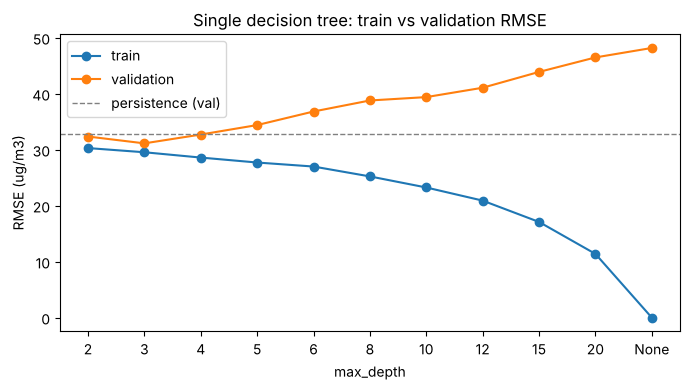

{'model': 'Decision tree (depth 3, change)',
 'train RMSE': np.float64(29.543210289362626),
 'val RMSE': np.float64(31.13231502640733),
 'val MAE': np.float64(17.16752273659391),
 'Sep': np.float64(21.480100506576626),
 'Oct': np.float64(18.95216385513652),
 'Nov': np.float64(45.90662735324328),
 'bias': -1.1325905715287152}

In [27]:
def back(z, target, persist):
    if target == "level":  return z
    if target == "change": return persist + z
    if target == "log":    return np.expm1(z)
    raise ValueError(target)

def target_values(target):
    return {"level": y_train, "change": y_train - p_train, "log": np.log1p(y_train)}[target]

def score_row(name, pred_tr, pred_va):
    va = evaluate(pred_va, y_val, T_val)
    return {"model": name, "train RMSE": rmse_clipped(pred_tr, y_train) if pred_tr is not None else np.nan, "val RMSE": va["RMSE"], "val MAE": va["MAE"],
            "Sep": va["RMSE Sep"], "Oct": va["RMSE Oct"], "Nov": va["RMSE Nov"], "bias": float(np.mean(np.clip(pred_va, 0, None) - y_val))}

depths = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train - p_train)
    rows.append({"max_depth": "None" if d is None else d, "leaves": tree.get_n_leaves(),
                 "train RMSE": rmse_clipped(p_train + tree.predict(X_train), y_train), "val RMSE": rmse_clipped(p_val + tree.predict(X_val), y_val)})
dt_sweep = pd.DataFrame(rows); display(dt_sweep.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(dt_sweep))
ax.plot(x, dt_sweep["train RMSE"], marker="o", label="train"); ax.plot(x, dt_sweep["val RMSE"], marker="o", label="validation")
ax.axhline(32.75, color="grey", ls="--", lw=1, label="persistence (val)")
ax.set_xticks(list(x)); ax.set_xticklabels(dt_sweep["max_depth"]); ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE (ug/m3)")
ax.set_title("Single decision tree: train vs validation RMSE"); ax.legend(); fig.tight_layout(); plt.show()

best_d = dt_sweep.loc[dt_sweep["val RMSE"].idxmin(), "max_depth"]; best_d = None if best_d == "None" else int(best_d)
tree = DecisionTreeRegressor(max_depth=best_d, random_state=SEED).fit(X_train, y_train - p_train)
tree_va = p_val + tree.predict(X_val)
tree_row = score_row(f"Decision tree (depth {best_d}, change)", p_train + tree.predict(X_train), tree_va)
tree_row

#### Gradient boosting: which target?
Same model, three targets. `staged_predict` gives the forecast after every boosting iteration, so one fit shows the whole train/validation curve.

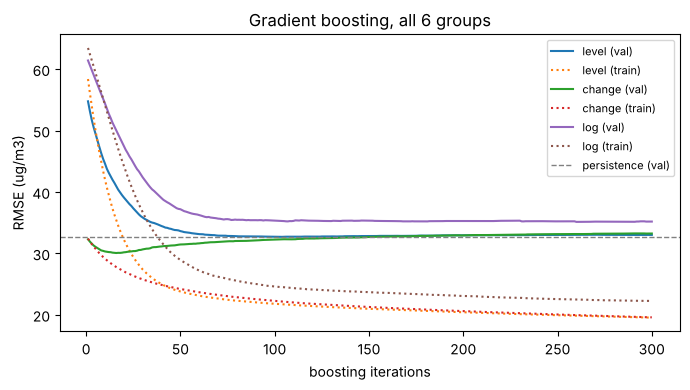

,best iter,train at best,val at best,val at 300
level,104.0,21.72,32.69,33.01
change,16.0,27.77,30.06,33.24
log,263.0,22.48,35.13,35.18


In [28]:
def hgb_curve(cols, target, **params):
    model = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **params).fit(X_train[:, cols], target_values(target))
    rows = []
    for i, (zt, zv) in enumerate(zip(model.staged_predict(X_train[:, cols]), model.staged_predict(X_val[:, cols])), start=1):
        rows.append({"iter": i, "train": rmse_clipped(back(zt, target, p_train), y_train), "val": rmse_clipped(back(zv, target, p_val), y_val)})
    return model, pd.DataFrame(rows)

BASE = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50)
curves = {}
fig, ax = plt.subplots(figsize=(7, 4))
for target in ["level", "change", "log"]:
    _, curves[target] = hgb_curve(ALL_COLS, target, **BASE)
    c = curves[target]
    ax.plot(c["iter"], c["val"], label=f"{target} (val)"); ax.plot(c["iter"], c["train"], ls=":", label=f"{target} (train)")
ax.axhline(32.75, color="grey", ls="--", lw=1, label="persistence (val)")
ax.set_xlabel("boosting iterations"); ax.set_ylabel("RMSE (ug/m3)"); ax.set_title("Gradient boosting, all 6 groups"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
pd.DataFrame({t: {"best iter": int(c.loc[c.val.idxmin(), "iter"]), "train at best": c.loc[c.val.idxmin(), "train"], "val at best": c.val.min(),
                  "val at 300": c.val.iloc[-1]} for t, c in curves.items()}).T.round(2)

#### Diagnosis: why do the trees overfit?
The `network` features take only 242 distinct values in training (one per day). A tree can split on them to isolate individual training days and learn what happened next on exactly those days, which does not carry over to new days. Test: refit without the `network` group.

In [29]:
NO_NET = [c for g, cols in groups.items() if g != "network" for c in cols]
diag = []
for label, cols in [("all 6 groups", ALL_COLS), ("without network", NO_NET)]:
    for target in ["level", "change"]:
        _, c = hgb_curve(cols, target, **BASE)
        best = c.loc[c.val.idxmin()]
        diag.append({"features": label, "target": target, "best iter": int(best["iter"]), "train at best": best["train"],
                     "val at best": best["val"], "val at 300": c.val.iloc[-1]})
pd.DataFrame(diag).round(2)

,features,target,best iter,train at best,val at best,val at 300
0,all 6 groups,level,104,21.72,32.69,33.01
1,all 6 groups,change,16,27.77,30.06,33.24
2,without network,level,79,25.42,29.72,30.10
3,without network,change,43,27.20,29.08,29.92


#### Tuning gradient boosting (without `network`, change target)
Small grid; the number of iterations is chosen on validation from the staged curve. `min_samples_leaf` is the main brake on memorising days (a leaf must contain many rows).

In [30]:
grid = []
for leaves in [15, 31]:
    for msl in [50, 500, 2000]:
        for loss in ["squared_error", "absolute_error"]:
            _, c = hgb_curve(NO_NET, "change", max_iter=400, learning_rate=0.05, max_leaf_nodes=leaves, min_samples_leaf=msl, loss=loss)
            best = c.loc[c.val.idxmin()]
            grid.append({"max_leaf_nodes": leaves, "min_samples_leaf": msl, "loss": loss, "best iter": int(best["iter"]),
                         "train at best": best["train"], "val at best": best["val"]})
hgb_grid = pd.DataFrame(grid).sort_values("val at best"); display(hgb_grid.round(2))

top = hgb_grid.iloc[0]
HGB_PARAMS = dict(max_iter=int(top["best iter"]), learning_rate=0.05, max_leaf_nodes=int(top["max_leaf_nodes"]),
                  min_samples_leaf=int(top["min_samples_leaf"]), loss=top["loss"])
hgb = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **HGB_PARAMS).fit(X_train[:, NO_NET], y_train - p_train)
hgb_tr, hgb_va = p_train + hgb.predict(X_train[:, NO_NET]), p_val + hgb.predict(X_val[:, NO_NET])
hgb_row = score_row("Gradient boosting (no network, change)", hgb_tr, hgb_va)
print(HGB_PARAMS); hgb_row

,max_leaf_nodes,min_samples_leaf,loss,best iter,train at best,val at best
0,15,50,squared_error,64,27.44,29.05
6,31,50,squared_error,43,27.20,29.08
2,15,500,squared_error,74,27.68,29.16
8,31,500,squared_error,46,27.68,29.32
1,15,50,absolute_error,119,28.34,29.54
4,15,2000,squared_error,106,28.18,29.57
10,31,2000,squared_error,148,27.71,29.67
7,31,50,absolute_error,75,28.29,29.72
3,15,500,absolute_error,83,28.94,29.73
9,31,500,absolute_error,73,28.61,29.83


{'max_iter': 64, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50, 'loss': 'squared_error'}


{'model': 'Gradient boosting (no network, change)',
 'train RMSE': np.float64(27.44062605157623),
 'val RMSE': np.float64(29.047909855523812),
 'val MAE': np.float64(16.27671574033882),
 'Sep': np.float64(19.820733028859042),
 'Oct': np.float64(17.966224996964186),
 'Nov': np.float64(42.8142853499332),
 'bias': -1.5588036382314452}

#### Random forest (without `network`, change target)
Each tree sees a bootstrap half of the rows (`max_samples=0.5`) and a random subset of features at each split (`max_features`); averaging 200 such trees lowers variance. This is the slowest cell of the notebook.

In [31]:
rf_rows = []
for msl in [20, 100, 500]:
    for mf in [0.33, 0.66]:
        t0 = time.time()
        rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=msl, max_features=mf, max_samples=0.5, n_jobs=-1,
                                   random_state=SEED).fit(X_train[:, NO_NET], y_train - p_train)
        rf_rows.append({"min_samples_leaf": msl, "max_features": mf, "train RMSE": rmse_clipped(p_train + rf.predict(X_train[:, NO_NET]), y_train),
                        "val RMSE": rmse_clipped(p_val + rf.predict(X_val[:, NO_NET]), y_val), "seconds": round(time.time() - t0)})
rf_grid = pd.DataFrame(rf_rows).sort_values("val RMSE"); display(rf_grid.round(2))

top = rf_grid.iloc[0]
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=int(top["min_samples_leaf"]), max_features=float(top["max_features"]),
                 max_samples=0.5, n_jobs=-1, random_state=SEED)
rf = RandomForestRegressor(**RF_PARAMS).fit(X_train[:, NO_NET], y_train - p_train)
rf_tr, rf_va = p_train + rf.predict(X_train[:, NO_NET]), p_val + rf.predict(X_val[:, NO_NET])
rf_row = score_row("Random forest (no network, change)", rf_tr, rf_va)
print(RF_PARAMS); rf_row

,min_samples_leaf,max_features,train RMSE,val RMSE,seconds
3,100,0.66,27.30,29.24,80
0,20,0.33,24.89,29.28,55
2,100,0.33,27.66,29.30,42
1,20,0.66,24.41,29.49,102
5,500,0.66,29.18,29.75,60
4,500,0.33,29.46,29.92,31


{'n_estimators': 200, 'min_samples_leaf': 100, 'max_features': 0.66, 'max_samples': 0.5, 'n_jobs': -1, 'random_state': 0}


{'model': 'Random forest (no network, change)',
 'train RMSE': np.float64(27.302471366390236),
 'val RMSE': np.float64(29.237918862709257),
 'val MAE': np.float64(16.503343592299167),
 'Sep': np.float64(19.631811252527843),
 'Oct': np.float64(18.61197958820387),
 'Nov': np.float64(43.00816478524593),
 'bias': -2.222878522455982}

#### Ablation of the best tree model
Same hyper-parameters; drop one feature group at a time (the `network` row shows what adding it back does).

In [32]:
use_hgb = hgb_row["val RMSE"] <= rf_row["val RMSE"]
def tree_fit_predict(cols):
    m = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **HGB_PARAMS) if use_hgb else RandomForestRegressor(**RF_PARAMS)
    return p_val + m.fit(X_train[:, cols], y_train - p_train).predict(X_val[:, cols])

base_val = (hgb_row if use_hgb else rf_row)["val RMSE"]
abl = [{"setting": "final (no network)", "n_features": len(NO_NET), "val RMSE": base_val, "delta": 0.0}]
for g, cols in groups.items():
    use, label = (sorted(NO_NET + cols), "+ network") if g == "network" else ([c for c in NO_NET if c not in cols], f"- {g}")
    v = rmse_clipped(tree_fit_predict(use), y_val)
    abl.append({"setting": label, "n_features": len(use), "val RMSE": v, "delta": v - base_val})
print("model:", "gradient boosting" if use_hgb else "random forest")
pd.DataFrame(abl).round(2)

model: gradient boosting


,setting,n_features,val RMSE,delta
0,final (no network),22,29.05,0.00
1,- own,10,29.35,0.31
2,- prevday,21,29.04,-0.00
3,- nbr,17,29.26,0.21
4,+ network,25,31.17,2.12
5,- trend,19,29.17,0.12
6,- long,21,29.08,0.04


In [33]:
best_tree_va = hgb_va if use_hgb else rf_va
print("best tree model minus Part 1 ridge, 95% block-bootstrap:", block_bootstrap_interval(daily_squared_error(best_tree_va), daily_squared_error(others["Ridge (Part 1)"])))
print("best tree model minus final Laplace model:               ", block_bootstrap_interval(daily_squared_error(best_tree_va), final_squared_error))

best tree model minus Part 1 ridge, 95% block-bootstrap: [-1.12 -0.23  0.53]
best tree model minus final Laplace model:                [0.1  0.66 1.32]


**Interpretation (trees).**

*Single tree: overfitting in its plainest form.* As depth grows, training RMSE falls steadily (30.29 at depth 2, 0.00 with no depth limit) while validation RMSE is best at depth 3 (31.13) and then climbs to 48.18. A deep tree ends up with almost one leaf per training row (108,657 leaves), so it memorises the training days instead of learning rules that carry over. Even the best single tree loses to Part 1 ridge (31.13 vs 29.58): one tree is too coarse at shallow depth and too noisy at large depth.

*Target.* Change from persistence works best for trees: the model only has to learn how tomorrow differs from today, and anything it cannot explain falls back to persistence. The level target is worse (best 32.69) and the log target is clearly worst (35.13), because a tree trained on log values predicts an average in log space, which back-transforms to something close to the median and under-predicts the mean that RMSE rewards.

*Why the trees overfit: day-level features.* The `network` group is the same number for all 468 stations on a given day, so in training it takes only 242 distinct values. A tree can split on it to isolate individual training days and learn what happened next on exactly those days. That does not transfer to new days. Removing `network` lowers validation RMSE from 30.06 to 29.08 (change target), and in the ablation adding it back costs +2.12 RMSE. For the linear models the same group was the most useful one (+0.82 when removed in the *Ablation* subsection): a linear model can only use it as one smooth slope, so it cannot memorise days with it. The same information helps a low-variance model and hurts a high-variance one.

*Tuned ensembles.* Gradient boosting (shallow trees with 15 leaves, at least 50 rows per leaf, 64 iterations) reaches validation RMSE 29.05 and MAE 16.28; the random forest (200 trees, at least 100 rows per leaf) reaches 29.24 and 16.50. In both, validation is best with few iterations or large leaves, and more capacity only lowers training error. Absolute loss did not help boosting (every absolute-loss setting scored worse than its squared-loss twin), unlike for the linear model; trees already limit the influence of outliers by averaging within leaves.

*Did a more flexible model beat ridge? (task question 2).* Partly. The ensembles beat persistence clearly and Part 1 ridge on MAE (16.28 vs 18.16), but on RMSE the gap to Part 1 ridge is within noise (block-bootstrap 95% interval for gradient boosting minus ridge: about [−1.15, +0.53]). They lose to the improved linear models: the Laplace model is better by about 0.66 RMSE (interval about [+0.08, +1.31]). Every tree model fits the training months better than it fits validation (gap +1.6 to +1.9 RMSE, against about 0.15 for the Laplace model). Two reasons: (1) trees have far more capacity than a linear model and use it to fit day-specific patterns, which a training set of only 242 distinct days cannot pin down; (2) trees predict averages of training leaves, so they cannot extrapolate a trend, while a linear model in log space scales its forecast with the current level, which suits the rising Sep to Nov season.

*Ablation of the best tree.* `own` (+0.31) and `nbr` (+0.21) matter most, then `trend` (+0.12); `long` (+0.04) and `prevday` (0.00) add nothing because their information is already in the other groups. As for the linear models, neighbourhood information carries signal, but for trees region-wide information only helps as station-level features, not as day-level constants.

### Weighted k-NN analog forecasting
**Idea (analog forecasting).** Find past (station, day) pairs whose recent history looks like today's and use how they evolved. Weighted k-NN (`weights='distance'`) on standardised features (scaler fitted on training rows only), predicting the **change from persistence**, `delta = y(t+24h) − y(t)`, and reconstructing `max(0, y(t) + delta)`. A k-NN is an interpolator and cannot predict beyond the largest value among its neighbours, so predicting raw PM2.5 would badly underestimate November extremes that summer training days never reach; predicting the change lets it adapt to a shifting local baseline.

Its own 16 raw (not log) features are in 6 groups: `own_lags` (lag 0 and lag 1 h, 2 columns), `own_summary` (mean/min/max/std of those 2 h, 4), `trend` (18 h change, 6 h-vs-6 h momentum, deviation from the 18 h mean, 3), `spatial_nbr` (75-nearest mean now and over 18 h, local anomaly, 3), `network` (network mean and 24 h change, 2) and `calendar` (sin/cos of day of year, 2).

Implementation note: instead of calling `KNeighborsRegressor` once for each k, the neighbours are searched once for the largest k and the distance-weighted mean is formed for every k from the sorted neighbour list. This is mathematically the same estimator (inverse-distance weights) and makes the k-sweeps cheap.

In [34]:
from sklearn.neighbors import NearestNeighbors

A75 = neighbour_matrix(stations, 75)

def knn_features(W, T):
    L = lag_stack(W, T, 24)
    now = L[:, :, 0]
    flat = lambda a: a.reshape(-1, 1)
    own_lags = L[:, :, :2].reshape(-1, 2)
    own_summary = np.column_stack([flat(s) for s in (L[:, :, :2].mean(2), L[:, :, :2].min(2), L[:, :, :2].max(2), L[:, :, :2].std(2))])
    trend = np.column_stack([flat(now - L[:, :, 17]), flat(L[:, :, :6].mean(2) - L[:, :, 6:12].mean(2)), flat(now - L[:, :, :18].mean(2))])
    nbr_now = now @ A75.T
    spatial = np.column_stack([flat(nbr_now), flat(L[:, :, :18].mean(2) @ A75.T), flat(now - nbr_now)])
    network = np.column_stack([np.repeat(c, N) for c in (now.mean(1), now.mean(1) - L[:, :, 23].mean(1))])
    phase = 2 * np.pi * (pd.DatetimeIndex(T).dayofyear.to_numpy() - 1) / 365
    calendar = np.column_stack([np.repeat(np.sin(phase), N), np.repeat(np.cos(phase), N)])
    blocks = [("own_lags", own_lags), ("own_summary", own_summary), ("trend", trend), ("spatial_nbr", spatial), ("network", network), ("calendar", calendar)]
    X = np.column_stack([b for _, b in blocks]); grp, start = {}, 0
    for name, b in blocks:
        grp[name] = list(range(start, start + b.shape[1])); start += b.shape[1]
    assert not np.isnan(X).any()
    return X, grp

Xk_train, knn_groups = knn_features(W, T_train)
Xk_val, _ = knn_features(W, T_val)
assert Xk_train.shape == (113_256, 16) and Xk_val.shape == (42_588, 16)
t = T_val[10]                                                                                # leakage and parity
assert np.allclose(knn_features(W, [t])[0], knn_features(W.loc[:t], [t])[0])
assert np.allclose(knn_features(W, [t])[0], Xk_val[10 * N:11 * N])
print({g: len(c) for g, c in knn_groups.items()})

dy_train = y_train - p_train

def knn_curve(cols, ks):
    # distance-weighted k-NN on standardised features for every k in ks, from one neighbour search
    sc = StandardScaler().fit(Xk_train[:, cols])
    nn = NearestNeighbors(n_neighbors=max(ks), algorithm="kd_tree", n_jobs=-1).fit(sc.transform(Xk_train[:, cols]))
    dist, idx = nn.kneighbors(sc.transform(Xk_val[:, cols]))
    zero = dist == 0
    w = np.where(zero.any(axis=1, keepdims=True), zero.astype(float), 1.0 / np.where(zero, 1.0, dist))
    cw, cwy = np.cumsum(w, axis=1), np.cumsum(w * dy_train[idx], axis=1)
    return {k: np.clip(p_val + cwy[:, k - 1] / cw[:, k - 1], 0, None) for k in ks}

def knn_table(preds_by_k):
    return pd.DataFrame({k: {m: v for m, v in evaluate(p, y_val, T_val).items() if m in ["RMSE", "MAE", "RMSE Sep", "MAE Sep", "RMSE Oct", "MAE Oct", "RMSE Nov", "MAE Nov"]}
                         for k, p in preds_by_k.items()}).T.rename_axis("k")

{'own_lags': 2, 'own_summary': 4, 'trend': 3, 'spatial_nbr': 3, 'network': 2, 'calendar': 2}


#### Stage 1: choose k on the full 16 features, then ablate at that k
Validation RMSE against k on all 16 features, then a drop-one-group ablation with the same k.

,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
k,,,,,,,,
100,30.41,17.56,20.08,8.46,18.72,12.01,45.16,32.41
200,29.95,17.18,20.00,8.39,18.48,11.76,44.37,31.59
300,29.80,17.02,20.01,8.36,18.44,11.66,44.08,31.21
400,29.75,16.92,20.08,8.35,18.42,11.61,43.93,30.98
500,29.73,16.87,20.18,8.35,18.44,11.60,43.85,30.83
550,29.73,16.85,20.23,8.36,18.46,11.59,43.82,30.78
700,29.76,16.81,20.38,8.37,18.50,11.58,43.78,30.65


stage-1 k used for the ablation: 550


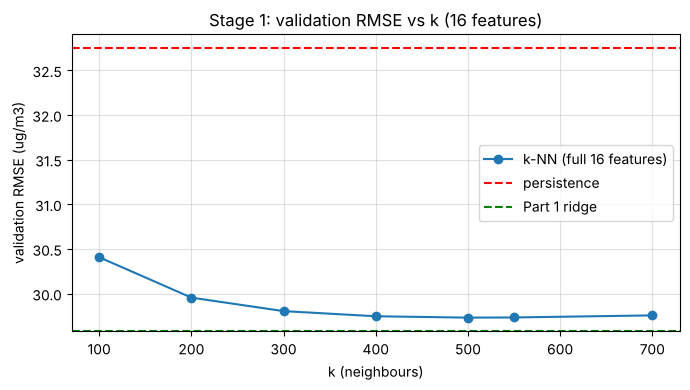

In [35]:
all16 = list(range(16))
stage1 = knn_curve(all16, [100, 200, 300, 400, 500, 550, 700])
df_k1 = knn_table(stage1); display(df_k1.round(2))
best_k_initial = 550      # validation RMSE is flat at 29.73 for k = 450 to 600; 550 has the lowest November error on that plateau
print("stage-1 k used for the ablation:", best_k_initial)

plt.figure(figsize=(7, 4))
plt.plot(df_k1.index, df_k1["RMSE"], marker="o", label="k-NN (full 16 features)")
plt.axhline(32.75, color="red", ls="--", label="persistence"); plt.axhline(29.58, color="green", ls="--", label="Part 1 ridge")
plt.xlabel("k (neighbours)"); plt.ylabel("validation RMSE (ug/m3)"); plt.title("Stage 1: validation RMSE vs k (16 features)"); plt.grid(alpha=0.4); plt.legend()
plt.tight_layout(); plt.show()

In [36]:
def knn_score(cols, k):
    return evaluate(knn_curve(cols, [k])[k], y_val, T_val)

full_k = round(df_k1.loc[best_k_initial, "RMSE"], 2)
rows = [{"group removed": "none (full model, 6 groups)", "features left": 16, "val RMSE": full_k, "val MAE": round(df_k1.loc[best_k_initial, "MAE"], 2), "delta RMSE": 0.0}]
for g, drop in knn_groups.items():
    keep = [c for c in range(16) if c not in drop]; s = knn_score(keep, best_k_initial)
    rows.append({"group removed": g, "features left": len(keep), "val RMSE": round(s["RMSE"], 2), "val MAE": round(s["MAE"], 2), "delta RMSE": round(s["RMSE"] - full_k, 2)})
core4 = knn_groups["own_lags"] + knn_groups["own_summary"] + knn_groups["trend"] + knn_groups["spatial_nbr"]
final8 = knn_groups["own_lags"] + knn_groups["trend"] + knn_groups["spatial_nbr"]
for label, cols in [("network + calendar (core 4 groups, 12 features)", core4), ("network + calendar + own_summary (8 features)", final8)]:
    s = knn_score(cols, best_k_initial)
    rows.append({"group removed": label, "features left": len(cols), "val RMSE": round(s["RMSE"], 2), "val MAE": round(s["MAE"], 2), "delta RMSE": round(s["RMSE"] - full_k, 2)})
pd.DataFrame(rows)

,group removed,features left,val RMSE,val MAE,delta RMSE
0,"none (full model, 6 groups)",16,29.73,16.85,0.00
1,own_lags,14,29.75,16.86,0.02
2,own_summary,12,29.74,16.90,0.01
3,trend,13,30.62,17.41,0.89
4,spatial_nbr,13,30.16,17.16,0.43
5,network,14,29.79,17.04,0.06
6,calendar,14,29.48,16.37,-0.25
7,"network + calendar (core 4 groups, 12 features)",12,29.25,16.37,-0.48
8,network + calendar + own_summary (8 features),8,29.17,16.33,-0.56


#### Stage 2: re-tune k on the pruned 8-feature set
The ablation shows `calendar` and `network` hurt (out-of-distribution seasonal angles; a state-wide average that flattens regional differences and, in November, is many standard deviations above the summer mean, so it dominates the distance), and `own_summary` repeats `own_lags` (statistics of the same two hours) and gives half of the distance to micro-scale noise. Pruning leaves `own_lags + trend + spatial_nbr` (2 : 3 : 3). k is then re-tuned on this set.

,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
k,,,,,,,,
100,29.25,16.52,19.86,8.08,18.30,11.60,43.06,30.05
150,29.19,16.45,19.80,8.04,18.23,11.54,43.00,29.94
200,29.14,16.42,19.74,8.03,18.19,11.51,42.95,29.88
250,29.12,16.38,19.75,8.02,18.17,11.48,42.91,29.82
300,29.12,16.37,19.75,8.02,18.16,11.46,42.91,29.79
350,29.13,16.35,19.77,8.02,18.16,11.45,42.92,29.76
400,29.13,16.34,19.79,8.02,18.17,11.45,42.91,29.72


stage-2 best k (first minimum at 2 decimals): 250


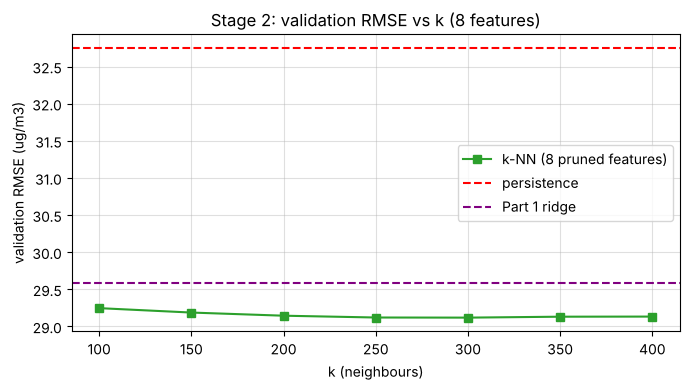

In [37]:
stage2 = knn_curve(final8, [100, 150, 200, 250, 300, 350, 400])
df_k2 = knn_table(stage2); display(df_k2.round(2))
best_k_final = int(df_k2["RMSE"].round(2).idxmin()); print("stage-2 best k (first minimum at 2 decimals):", best_k_final)
knn_va = stage2[best_k_final]

plt.figure(figsize=(7, 4))
plt.plot(df_k2.index, df_k2["RMSE"], marker="s", color="tab:green", label="k-NN (8 pruned features)")
plt.axhline(32.75, color="red", ls="--", label="persistence"); plt.axhline(29.58, color="purple", ls="--", label="Part 1 ridge")
plt.xlabel("k (neighbours)"); plt.ylabel("validation RMSE (ug/m3)"); plt.title("Stage 2: validation RMSE vs k (8 features)"); plt.grid(alpha=0.4); plt.legend()
plt.tight_layout(); plt.show()

**Interpretation (k-NN).** `trend` is the most useful group (+0.89 RMSE when removed): the 18 h change and the 6 h-vs-6 h momentum say whether the air is clearing or building up, which is what analogs need to match. `spatial_nbr` is second (+0.43): the 75-station mean is a regional level and the local anomaly separates local from regional pollution. `own_lags` and `own_summary` are redundant with each other (the group dropped alone changes almost nothing). `network` is nearly neutral and `calendar` hurts (training days are 1 to 244 and validation days 245 to 335, so the angles are out of range and spuriously pull neighbours towards late August). The pruned model gets about 29.1 / 16.4 RMSE / MAE with k = 250 to 300, better than Part 1 ridge in every month (29.58 / 18.16); the k-curve is flat above k ≈ 200. The model is a non-parametric interpolator and therefore needs the change-from-persistence target: with that, it is good for the typical day (Sep/Oct MAE below the ridge's) but, as for the trees, it cannot extrapolate beyond the training range and does worse than the linear log model in November.

### Clustering stations
**Idea (lecture 14).** Group the 468 stations into clusters that behave alike, then use the clusters in two ways: (1) **per-cluster models** (a separate Laplace model for each cluster, between one pooled model and 468 per-station models); (2) **cluster features** (one pooled model plus, for each station, the current level of *its cluster*, next to the distance-based neighbours it already has).

Base model: the final Laplace model and its 25 features, so every comparison isolates the effect of the clusters. **No leakage:** station profiles are computed from training hours only (up to 31 Aug 12:00); cluster features at issue time t use readings at or before t.

Each station is described by numbers computed on log PM2.5 over Jan to Aug: **monthly** (its mean level in each month, 8 numbers), **diurnal** (its mean by hour of day minus its overall mean, 24 numbers: shape of the daily cycle), **location** (x, y in km). Profiles are standardised so every column counts equally.

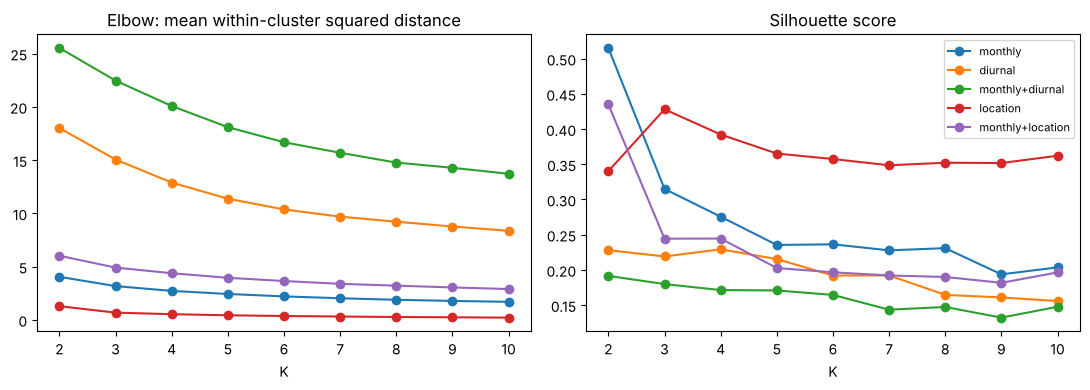

,2,3,4,5,6,7,8,9,10
monthly,0.515,0.315,0.276,0.235,0.236,0.228,0.231,0.194,0.204
diurnal,0.228,0.219,0.229,0.215,0.192,0.192,0.165,0.161,0.156
monthly+diurnal,0.191,0.180,0.171,0.171,0.164,0.143,0.147,0.132,0.148
location,0.340,0.428,0.392,0.365,0.357,0.349,0.352,0.352,0.362
monthly+location,0.435,0.244,0.245,0.203,0.197,0.192,0.190,0.182,0.196


In [38]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

W_tr = np.log1p(W.loc[:"2024-08-31 12:00"])
monthly = W_tr.groupby(W_tr.index.month).mean().T.to_numpy()
diurnal = W_tr.groupby(W_tr.index.hour).mean().T
diurnal = diurnal.sub(diurnal.mean(axis=1), axis=0).to_numpy()
location = stations[["x_km", "y_km"]].to_numpy()
PROFILES = {"monthly": monthly, "diurnal": diurnal, "monthly+diurnal": np.hstack([monthly, diurnal]), "location": location,
            "monthly+location": np.hstack([monthly, location])}
PROFILES_Z = {k: StandardScaler().fit_transform(v) for k, v in PROFILES.items()}

Ks = range(2, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); sil_table = {}
for name, Z in PROFILES_Z.items():
    inertia, sil = [], []
    for K in Ks:
        km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
        inertia.append(km.inertia_ / len(Z)); sil.append(silhouette_score(Z, km.labels_))
    axes[0].plot(list(Ks), inertia, marker="o", label=name); axes[1].plot(list(Ks), sil, marker="o", label=name)
    sil_table[name] = dict(zip(Ks, np.round(sil, 3)))
axes[0].set_title("Elbow: mean within-cluster squared distance"); axes[0].set_xlabel("K")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("K"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
pd.DataFrame(sil_table).T

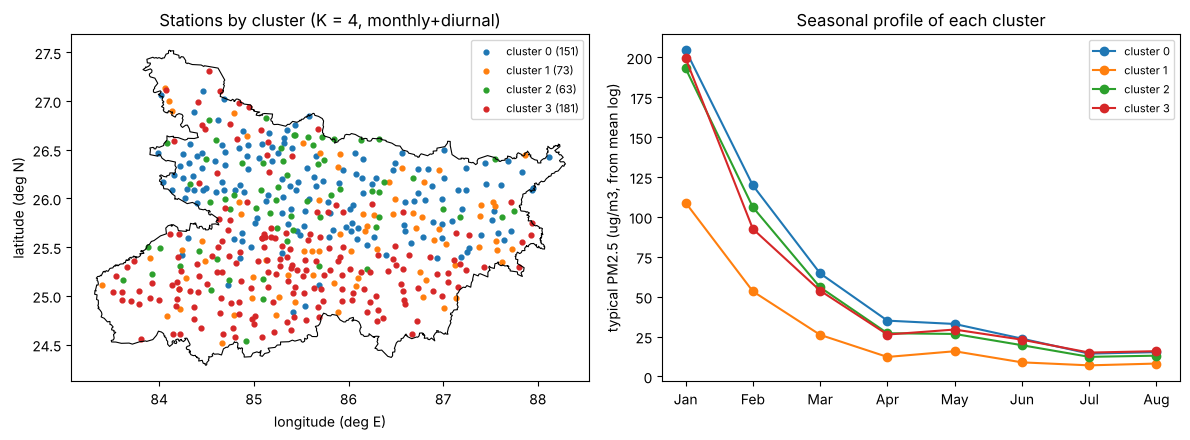

In [39]:
boundary = pd.read_csv(DATA_DIR / "bihar_boundary.csv")
K_SHOW = 4
lab_show = KMeans(K_SHOW, n_init=10, random_state=SEED).fit_predict(PROFILES_Z["monthly+diurnal"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(boundary.iloc[:, 0], boundary.iloc[:, 1], color="black", lw=0.8)
for k in range(K_SHOW):
    m = lab_show == k
    ax.scatter(stations.longitude[m], stations.latitude[m], s=12, label=f"cluster {k} ({m.sum()})")
ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("latitude (deg N)"); ax.set_title("Stations by cluster (K = 4, monthly+diurnal)"); ax.legend(fontsize=8)
ax = axes[1]
for k in range(K_SHOW):
    ax.plot(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug"], np.expm1(monthly[lab_show == k].mean(axis=0)), marker="o", label=f"cluster {k}")
ax.set_ylabel("typical PM2.5 (ug/m3, from mean log)"); ax.set_title("Seasonal profile of each cluster"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

#### Use 1: a separate model for each cluster
Rows are split by their station's cluster; each cluster gets its own Laplace model (same features, same settings).

In [40]:
pred_pooled = final_pred_val                                   # the pooled Laplace model of the Final model subsection
def mae_val(p): return float(np.mean(np.abs(np.clip(p, 0, None) - y_val)))

def per_cluster_predict(labels):
    lab_tr, lab_va = np.tile(labels, len(T_train)), np.tile(labels, len(T_val))
    pred = np.zeros_like(y_val)
    for k in np.unique(labels):
        pred[lab_va == k] = LogLaplaceForecaster().fit(X_train[lab_tr == k], y_train[lab_tr == k]).predict(X_val[lab_va == k])
    return pred

rows = []
for name, Z in PROFILES_Z.items():
    for K in [2, 3, 5, 8]:
        labels = KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)
        p = per_cluster_predict(labels)
        rows.append({"profile": name, "K": K, "smallest cluster": int(np.bincount(labels).min()), "val RMSE": rmse_clipped(p, y_val), "val MAE": mae_val(p)})
per_cluster = pd.DataFrame(rows).sort_values("val RMSE")
print(f"pooled reference: {rmse_clipped(pred_pooled, y_val):.2f} / {mae_val(pred_pooled):.2f}")
per_cluster.round(2)

pooled reference: 28.16 / 15.74


,profile,K,smallest cluster,val RMSE,val MAE
4,diurnal,2,229,28.17,15.76
8,monthly+diurnal,2,208,28.21,15.78
16,monthly+location,2,105,28.21,15.73
0,monthly,2,107,28.21,15.73
9,monthly+diurnal,3,77,28.24,15.75
5,diurnal,3,125,28.26,15.83
12,location,2,222,28.32,15.80
1,monthly,3,65,28.35,15.80
10,monthly+diurnal,5,4,28.35,15.82
14,location,5,82,28.36,15.86


#### Use 2: pooled model plus cluster features
For each station and issue time t, three new features: the mean log PM2.5 of its cluster at t, the cluster's mean over the last 24 h, and the station's anomaly versus its cluster at t. A cluster is a group of stations that *behave* alike, which can be far apart; the existing `nbr` features use the nearest stations by distance. Hard version: k-means labels. Soft version: a Gaussian mixture model (GMM) where each station belongs to every cluster with a probability and the cluster mean is probability-weighted.

In [41]:
def cluster_features(T, weights):
    # weights: (468 x K) membership matrix (one-hot for k-means, probabilities for GMM)
    L = np.log1p(lag_stack(W, T, 24))
    now, m24 = L[:, :, 0], L.mean(axis=2)
    Wn = weights / weights.sum(axis=0, keepdims=True)
    c_now = (now @ Wn) @ weights.T / weights.sum(axis=1)
    c_24 = (m24 @ Wn) @ weights.T / weights.sum(axis=1)
    return np.column_stack([c_now.ravel(), c_24.ravel(), (now - c_now).ravel()])

def with_cluster_features(weights):
    Ftr, Fva = cluster_features(T_train, weights), cluster_features(T_val, weights)
    return LogLaplaceForecaster().fit(np.hstack([X_train, Ftr]), y_train).predict(np.hstack([X_val, Fva]))

rows = []
for name, Z in PROFILES_Z.items():
    for K in [3, 5, 8]:
        p = with_cluster_features(np.eye(K)[KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)])
        rows.append({"profile": name, "K": K, "clustering": "k-means", "val RMSE": rmse_clipped(p, y_val), "val MAE": mae_val(p)})
        p = with_cluster_features(GaussianMixture(K, covariance_type="diag", random_state=SEED, n_init=3).fit(Z).predict_proba(Z))
        rows.append({"profile": name, "K": K, "clustering": "GMM (soft)", "val RMSE": rmse_clipped(p, y_val), "val MAE": mae_val(p)})
cluster_feat = pd.DataFrame(rows).sort_values("val RMSE")
print(f"pooled reference: {rmse_clipped(pred_pooled, y_val):.2f} / {mae_val(pred_pooled):.2f}")
cluster_feat.round(2)

pooled reference: 28.16 / 15.74


,profile,K,clustering,val RMSE,val MAE
13,monthly+diurnal,3,GMM (soft),28.10,15.67
26,monthly+location,5,k-means,28.10,15.68
19,location,3,GMM (soft),28.11,15.69
12,monthly+diurnal,3,k-means,28.11,15.69
16,monthly+diurnal,8,k-means,28.11,15.68
28,monthly+location,8,k-means,28.11,15.69
21,location,5,GMM (soft),28.12,15.68
22,location,8,k-means,28.12,15.70
14,monthly+diurnal,5,k-means,28.13,15.68
18,location,3,k-means,28.13,15.72


In [42]:
best_pc = per_cluster.iloc[0]
pred_pc = per_cluster_predict(KMeans(int(best_pc.K), n_init=10, random_state=SEED).fit_predict(PROFILES_Z[best_pc.profile]))
best_cf = cluster_features_best = cluster_feat.iloc[0]
Zb, Kb = PROFILES_Z[best_cf.profile], int(best_cf.K)
weights = np.eye(Kb)[KMeans(Kb, n_init=10, random_state=SEED).fit_predict(Zb)] if best_cf.clustering == "k-means" \
    else GaussianMixture(Kb, covariance_type="diag", random_state=SEED, n_init=3).fit(Zb).predict_proba(Zb)
pred_cf = with_cluster_features(weights)
print(f"best per-cluster  ({best_pc.profile}, K={int(best_pc.K)}): {rmse_clipped(pred_pc, y_val):.2f}  minus pooled: {block_bootstrap_interval(daily_squared_error(pred_pc), final_squared_error)}")
print(f"best cluster-feat ({best_cf.profile}, K={Kb}, {best_cf.clustering}): {rmse_clipped(pred_cf, y_val):.2f}  minus pooled: {block_bootstrap_interval(daily_squared_error(pred_cf), final_squared_error)}")

best per-cluster  (diurnal, K=2): 28.17  minus pooled: [-0.09  0.01  0.1 ]
best cluster-feat (monthly+diurnal, K=3, GMM (soft)): 28.10  minus pooled: [-0.11 -0.05  0.03]


**Interpretation (clustering).** *Are there natural groups of stations? Only weakly.* Silhouette scores for the behaviour profiles are low: 0.13 to 0.23 for the diurnal and monthly + diurnal profiles at K = 3 to 10 (1 means well separated, 0 means stations sit between clusters). The one high value, monthly at K = 2 (0.52), just splits off a group of cleaner stations. Location clusters score higher (0.43 at K = 3), but only because k-means cuts a map into tidy regions. Stations form a continuum of behaviour rather than distinct types. With K = 4 on monthly + diurnal profiles, three clusters share almost the same seasonal curve (about 200 µg/m³ in January falling to 15 in July) and differ mainly in their daily cycle; one cluster (73 stations) sits at roughly half that level all year: cleaner sites spread across the whole state. Behaviour-based clusters therefore group stations that are far apart, which distance-based neighbours cannot do.

*A separate model per cluster does not help.* The best variant gives 28.17 against 28.16 for the pooled model, and larger K is worse (up to 28.62 at K = 8). Splitting the rows gives each model less data, and the pooled model already adapts to each station through its own features (its lags, 7-day mean and neighbours). Very small clusters (2 to 4 stations at K = 5 or 8) make it worse.

*Cluster features give a gain too small to trust.* The best variant reaches 28.10 / 15.67 against 28.16 / 15.74; almost every variant lands between 28.10 and 28.18, and the bootstrap interval for best variant minus pooled includes zero. The information in a cluster's current level is largely already in the neighbour and network features, since stations that behave alike are mostly polluted by the same regional air. Soft (GMM) and hard (k-means) clusters perform the same.

*Conclusion.* Clustering is a sound idea for adding station-type information, but here it does not improve on the pooled Laplace model by more than noise, so the pooled model stays final.

### All models side by side
Every model below was re-fitted in this notebook on the same training rows and scored on the same 42,588 validation rows. Training RMSE is shown for the models where a training forecast exists. "ΔRMSE vs final" is the paired block-bootstrap interval (7-day blocks) for RMSE(model) − RMSE(final model); an interval that includes 0 means the difference is not distinguishable from noise on 91 validation days.

,train RMSE,val RMSE,val MAE,Sep,Oct,Nov,bias,dRMSE vs final [95%]
model,,,,,,,,
Persistence,32.91,32.75,17.47,23.33,20.22,47.81,-0.47,[2.37 3.84 5.56]
Ridge (Part 1),NaN,29.58,18.16,20.34,19.36,43.06,5.32,[0.27 0.83 1.9 ]
Ridge own+network+trend+nbr,27.87,28.71,16.43,19.51,18.16,42.17,-0.48,[-0.14 0.22 0.88]
"Decision tree, depth 3",29.54,31.13,17.17,21.48,18.95,45.91,-1.13,[1.28 2.61 4.2 ]
"Random forest, no network",27.30,29.24,16.50,19.63,18.61,43.01,-2.22,[0.25 0.91 1.51]
"Gradient boosting, no network",27.44,29.05,16.28,19.82,17.97,42.81,-1.56,[0.1 0.66 1.32]
"Weighted k-NN, 8 features",NaN,29.12,16.38,19.75,18.17,42.91,-0.56,[0.03 0.71 1.37]
Per-cluster Laplace,NaN,28.17,15.76,19.91,17.56,41.14,-0.39,[-0.09 0.01 0.1 ]
Laplace + cluster features,NaN,28.10,15.67,20.07,17.51,40.94,-0.50,[-0.11 -0.05 0.03]


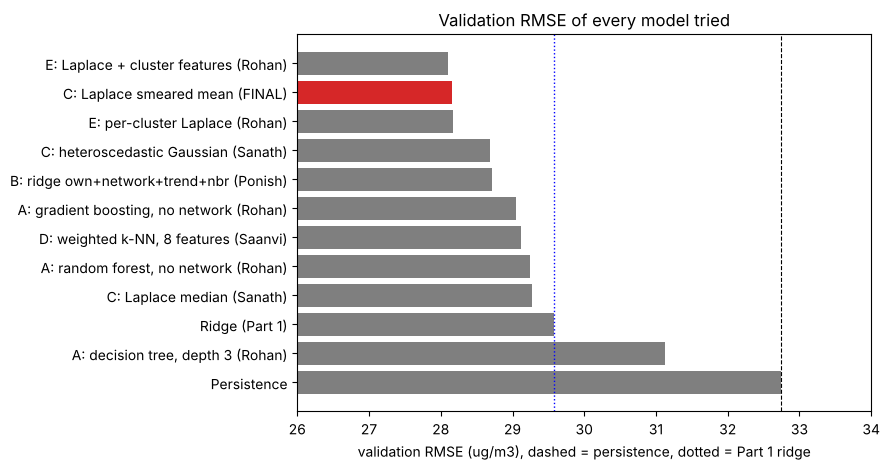

In [43]:
ridge_final_tr = fit_eval(SEL, 100)[1].predict(np.hstack([blk_tr_full[g][0] for g in SEL]))
entries = [
    ("Persistence", p_train, p_val),
    ("Ridge (Part 1)", None, part1_ridge_predict(W, stations, T_val)),
    ("Ridge own+network+trend+nbr", ridge_final_tr, ridge_final_pred),
    ("Decision tree, depth 3", p_train + tree.predict(X_train), tree_va),
    ("Random forest, no network", rf_tr, rf_va),
    ("Gradient boosting, no network", hgb_tr, hgb_va),
    ("Weighted k-NN, 8 features", None, knn_va),
    ("Per-cluster Laplace", None, pred_pc),
    ("Laplace + cluster features", None, pred_cf),
    ("Laplace median", train_predictions["Laplace median (MAE-optimal)"], final_predictions["Laplace median (MAE-optimal)"]),
    ("Heteroscedastic Gaussian", train_predictions["Heteroscedastic Gaussian"], final_predictions["Heteroscedastic Gaussian"]),
    ("Laplace smeared mean (FINAL)", train_predictions["Laplace smeared mean (FINAL)"], final_pred_val),
]
rows = []
for name, ptr, pva in entries:
    e = evaluate(pva, y_val, T_val)
    interval = "" if name.endswith("(FINAL)") else str(block_bootstrap_interval(daily_squared_error(pva), final_squared_error))
    rows.append({"model": name, "train RMSE": rmse_clipped(ptr, y_train) if ptr is not None else np.nan, "val RMSE": e["RMSE"], "val MAE": e["MAE"],
                 "Sep": e["RMSE Sep"], "Oct": e["RMSE Oct"], "Nov": e["RMSE Nov"], "bias": np.mean(np.clip(pva, 0, None) - y_val), "dRMSE vs final [95%]": interval})
all_models = pd.DataFrame(rows).set_index("model")
display(all_models.round(2))

fig, ax = plt.subplots(figsize=(9, 4.8))
order = all_models["val RMSE"].sort_values(ascending=False)
ax.barh(order.index, order.values, color=["tab:red" if n.endswith("(FINAL)") else "tab:gray" for n in order.index])
ax.axvline(all_models.loc["Persistence", "val RMSE"], color="k", ls="--", lw=0.8); ax.axvline(all_models.loc["Ridge (Part 1)", "val RMSE"], color="b", ls=":", lw=1)
ax.set_xlim(26, 34); ax.set_xlabel("validation RMSE (ug/m3), dashed = persistence, dotted = Part 1 ridge"); ax.set_title("Validation RMSE of every model tried")
plt.tight_layout(); plt.show()

### Answers to the Part 2 questions

**Summary.** The Laplace linear model on `log1p(PM2.5)` with the smeared-mean forecast gives validation RMSE 28.16 and MAE 15.74 (persistence 32.75 / 17.47, Part 1 ridge 29.58 / 18.16). It is better than both baselines in every month on both metrics (Sep 20.05 / 7.88, Oct 17.57 / 10.95, Nov 41.05 / 28.56). Training RMSE is 28.01 against 28.16 on validation, so it does not overfit.

**Question 1: What did each feature group add? Which ideas did not help, and why?**
The groups overlap (for example `local_anom = log(lag0) − log(neighbour mean)` already contains `lag0`), so we looked at drop-one (unique contribution) and at adding a group to `own` (total contribution).

| group (columns) | drop-one: RMSE / MAE worse by | added to `own`: RMSE / MAE better by | comment |
|---|---|---|---|
| `network` (3) | 0.82 / 0.44 | 1.06 / 0.60 | Biggest gain. The state-wide level and its 24 h change show if the whole region is going up or down, which one station cannot tell. It matters most when the season turns in November. |
| `nbr` (5) | 0.25 / 0.22 | 0.50 / 0.46 | Neighbour averages reduce sensor noise and separate local from regional pollution. |
| `long` (1) | 0.21 / 0.44 | 0.48 / 0.62 | A slow background level for the station. Helps MAE more than RMSE. |
| `own` (12) | 0.08 / 0.03 | alone: 29.93 / 17.20 | Looks unimportant in drop-one only because the other groups already contain `lag0`. |
| `trend` (3) | −0.01 / −0.01 | 0.14 / 0.06 | Mostly repeats `own`. |
| `prevday` (1) | 0.00 / −0.01 | 0.02 / 0.01 | No gain, yesterday's reading is already in the 24 h summaries. |

`prevday` and `trend` add nothing individually and nothing together (dropping both: 28.16 / 15.72 vs 28.16 / 15.74), so they overlap with `own`, `nbr` and `network` and are not needed. They are kept because removing them changes nothing, and they are two cheap features whose information (the same hour yesterday, momentum) is the kind that might matter on an unseen month; this is stated as a judgement, not as a validation gain.

Ideas that did not help:
- **Station climatology (`clim`).** RMSE got 0.12 worse. A station's training mean is mostly its January to August seasonal average, not a stable station identity, and recent readings and neighbours already show the spatial pattern. It is also a constant per station, so it says nothing about tomorrow.
- **30-day mean (`long30`).** RMSE 0.31 worse on validation, MAE 0.12 better, and no clear change in the rolling folds. In September and October a 30-day window still includes the low August levels, so it lags behind the rising season (the same reason `mean30d` hurt the ridge model in the *Ridge and lasso* subsection).
- **Calendar (`calendar`).** It hurt on validation (RMSE +1.79, MAE +2.48) and made MAE worse in all three rolling folds. Training only has days 3 to 244 of the year and validation has days 245 to 335, so the model has to extend a seasonal pattern learned in a falling season into a rising one. The same effect appeared in the ridge model (sin/cos columns gave a +5.3 bias) and the k-NN model.
- **Level target** (much worse, *Level target vs log target* subsection) and **squared loss in log space** (OLS gives 30.68 / 16.76 against 29.27 / 16.02 for the Laplace median).
- **Flexible models and clusters** (the tree, k-NN and clustering subsections): none beat the final model; see Question 2.

How the final set was chosen: we did use the validation ablation, so there is some selection. But the differences between feature sets are 0.1 to 0.35 RMSE and the gain over Ridge is 1.4. The first draft (with `clim`, without `long`) already scored 28.51 / 16.18, which beats both baselines, and the rolling check inside the training period supports dropping `calendar` and treating `clim` and `long30` as neutral.

**Question 2: Did a more flexible model beat ridge on validation? What about training?**
*A better linear model did; the flexible models did not beat the best linear one.* Against Part 1 ridge, the final model's RMSE is 28.16 vs 29.58 (1.42 lower, about 5%) and MAE is 15.74 vs 18.16 (2.42 lower, about 13%), better in every month on both metrics. The 95% bootstrap interval for the RMSE difference is [−1.90, −0.27], so it does not include zero. (The point estimate is −1.42; the bootstrap median is smaller because a few extreme November days dominate the squared error.) Against persistence the interval is [−5.56, −2.37]. This model is not more flexible than Part 1 ridge, since it is also linear, so the gain is not from extra capacity. It comes from the log transform (removes the skew), the Laplace likelihood (robust to big spikes and the right loss for MAE) and the smearing factor (turns the median back into a mean for RMSE).

The truly flexible models (tree and k-NN subsections) fit the training months better than the validation months: for the forest and boosting the training RMSE is 27.3 and 27.4 against 29.2 and 29.0 on validation (gap about +1.6 to +1.9), and a fully grown single tree has training RMSE 0.00 and validation RMSE 48.18. Trees have far more capacity than a linear model and use it to fit day-specific patterns that a training set of only 242 distinct days cannot pin down, and they predict averages of training leaves, so they cannot extrapolate: the rising Sep to Nov season sends the targets above anything the summer days contain. For the linear log model the gap is about 0.15 (28.01 vs 28.16). The forest and boosting beat Part 1 ridge on MAE but on RMSE only within noise, and both lose to the Laplace model (boosting minus Laplace: interval about [+0.08, +1.31]). k-NN (29.12 / 16.38) behaves the same way, and clustering the stations adds nothing beyond noise (28.10 vs 28.16). So the extra flexibility does not pay off here, and the main limit is the seasonal shift, not model capacity.

Median vs mean: the median forecast has MAE 16.02 and RMSE 29.27, and the smeared-mean forecast has RMSE 28.16 and MAE 15.74. Without a seasonal shift the median would win on MAE, but here it under-predicts on average (bias −6.0) and the smearing factor (about +12%) corrects part of that. The smeared mean is the reported forecast.

The heteroscedastic Gaussian (28.69 / 16.05) is slightly worse on point forecasts than the Laplace mean forecast (bootstrap interval for the RMSE difference about [−1.28, +0.01], borderline). What it adds is calibrated uncertainty: the 80% interval contains 83.8% of validation points (50% gives 54.8%, 90% gives 91.7%), validation negative log-likelihood is 0.629 vs 0.683 for constant variance, and the predicted spread follows the real monthly spread.

**Question 3: What information that we do not have would help most?**
- Weather: wind speed and direction, boundary layer height or temperature inversions, rainfall and humidity.
- Emissions: satellite fire counts for crop residue burning upwind, traffic and industrial activity.
- Coverage: readings from stations just outside Bihar, since part of the November increase probably comes from outside.

These would help most in autumn, when the season turns, which is where every model is weakest: the November RMSE (41 to 48) is about twice the September and October RMSE (17 to 23), and a handful of November smog days carry most of the squared error (for the ridge model, the top 10 of 30 November days carry about 61%).

**Final choice.** The Laplace linear model on `log1p` with the smeared-mean forecast, 25 features in 6 groups, `l2 = 1e-3`. It is used for Parts 3, 4 and 5.

## Part 3: Lead time
The target stays at **12:00 on day d+1**; only the issue time moves closer:

| lead | issue time |
|---|---|
| 24 h | 12:00 on day d (the main task) |
| 12 h | 00:00 on d+1 |
| 6 h | 06:00 on d+1 |
| 3 h | 09:00 on d+1 |
| 1 h | 11:00 on d+1 |

For every lead: (1) persistence = the reading at the issue time; (2) the Part 1 ridge with the same 29 features taken relative to the new issue time (same 24 h window ending at the issue time), refitted for that lead; (3) our Part 2 model, refitted for that lead with the same hyper-parameters. All features are computed from readings at or before the issue time, so the same code works for every lead. Training targets are 3 Jan to 31 Aug (113,256 rows at every lead) and validation targets are 1 Sep to 30 Nov (42,588 rows at every lead), so all leads are scored on exactly the same targets.

### Fit and score every method at every lead

In [44]:
LEADS = [1, 3, 6, 12, 24]
rows, preds = [], {}
laplace_models, X_vals, y_vals, T_vals = {}, {}, {}, {}
for lead in LEADS:
    T_tr_l, T_va_l = issue_times(lead)
    y_tr_l, y_va_l = targets(W, T_tr_l, lead), targets(W, T_va_l, lead)
    assert len(y_tr_l) == 113_256 and len(y_va_l) == 42_588
    t = T_va_l[10]                                                       # leakage check at this lead
    assert np.allclose(extract_features(W, [t], ctx)[0], extract_features(W.loc[:t], [t], ctx)[0]), f"leakage at lead {lead}"
    X_tr_l, X_va_l = extract_features(W, T_tr_l, ctx)[0], extract_features(W, T_va_l, ctx)[0]
    lap = LogLaplaceForecaster().fit(X_tr_l, y_tr_l)
    p = {"Persistence": persistence(W, T_va_l),
         "Ridge (Part 1, refitted)": part1_ridge_predict(W, stations, T_va_l, lead),
         "Laplace (Part 2, refitted)": lap.predict(X_va_l)}
    preds[lead] = p
    laplace_models[lead], X_vals[lead], y_vals[lead], T_vals[lead] = lap, X_va_l, y_va_l, T_va_l
    for method, pred in p.items():
        e = evaluate(pred, y_va_l, T_va_l, lead)
        rows.append({"lead (h)": lead, "issue time": f"{T_va_l[0]:%H:%M}" + (" (day d)" if lead == 24 else " (day d+1)"), "method": method,
                     "RMSE": e["RMSE"], "MAE": e["MAE"], "RMSE Sep": e["RMSE Sep"], "RMSE Oct": e["RMSE Oct"], "RMSE Nov": e["RMSE Nov"],
                     "bias": float(np.mean(np.clip(pred, 0, None) - y_va_l))})
    print(f"lead {lead:2d} h done (issue {T_va_l[0]:%H:%M}, smearing factor {lap.smearing_:.3f})")
results = pd.DataFrame(rows)
assert abs(results.query("method == 'Laplace (Part 2, refitted)' and `lead (h)` == 24")["RMSE"].item() - rmse_clipped(final_pred_val, y_val)) < 1e-9
results.pivot(index="lead (h)", columns="method", values="RMSE").round(2)

lead  1 h done (issue 11:00, smearing factor 1.066)


lead  3 h done (issue 09:00, smearing factor 1.106)


lead  6 h done (issue 06:00, smearing factor 1.126)


lead 12 h done (issue 00:00, smearing factor 1.127)


lead 24 h done (issue 12:00, smearing factor 1.119)


method,"Laplace (Part 2, refitted)",Persistence,"Ridge (Part 1, refitted)"
lead (h),,,
1,20.58,23.95,18.95
3,27.25,51.43,28.37
6,29.08,66.82,33.72
12,28.63,72.74,31.70
24,28.16,32.75,29.58


### Validation RMSE and MAE against lead time

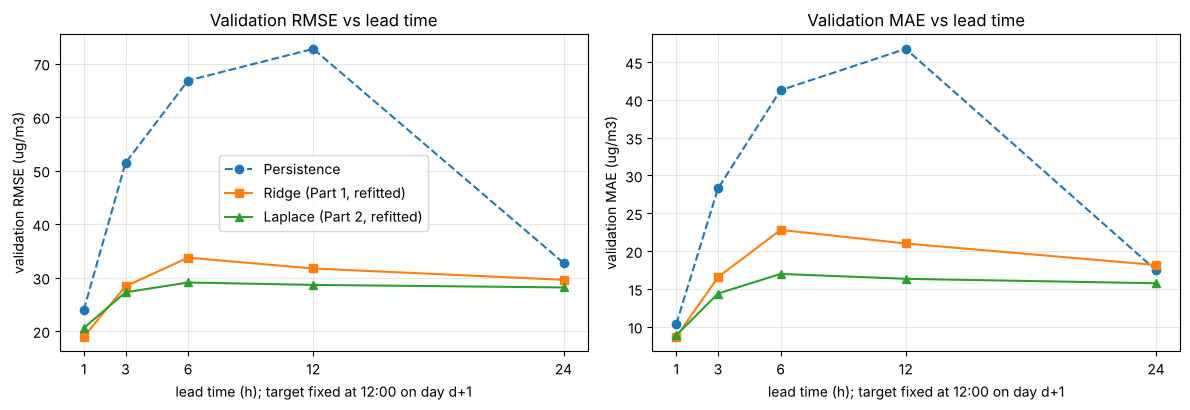

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric in zip(axes, ["RMSE", "MAE"]):
    for method, style in [("Persistence", "o--"), ("Ridge (Part 1, refitted)", "s-"), ("Laplace (Part 2, refitted)", "^-")]:
        d = results[results.method == method]
        ax.plot(d["lead (h)"], d[metric], style, label=method)
    ax.set_xticks(LEADS); ax.set_xlabel("lead time (h); target fixed at 12:00 on day d+1")
    ax.set_ylabel(f"validation {metric} (ug/m3)"); ax.set_title(f"Validation {metric} vs lead time"); ax.grid(alpha=0.3)
axes[0].legend(); fig.tight_layout(); plt.show()

### The 1-hour nowcast and the day-ahead forecast, reported separately

In [46]:
cols = ["method", "RMSE", "MAE", "RMSE Sep", "RMSE Oct", "RMSE Nov", "bias"]
print("1-hour lead (nowcast, issued 11:00 on day d+1)")
display(results[results["lead (h)"] == 1][cols].set_index("method").round(2))
print("24-hour lead (day-ahead, issued 12:00 on day d)")
display(results[results["lead (h)"] == 24][cols].set_index("method").round(2))

1-hour lead (nowcast, issued 11:00 on day d+1)


,RMSE,MAE,RMSE Sep,RMSE Oct,RMSE Nov,bias
method,,,,,,
Persistence,23.95,10.36,20.36,17.01,32.05,6.37
"Ridge (Part 1, refitted)",18.95,8.67,17.86,13.68,24.02,0.52
"Laplace (Part 2, refitted)",20.58,8.86,18.85,15.08,26.36,4.24


24-hour lead (day-ahead, issued 12:00 on day d)


,RMSE,MAE,RMSE Sep,RMSE Oct,RMSE Nov,bias
method,,,,,,
Persistence,32.75,17.47,23.33,20.22,47.81,-0.47
"Ridge (Part 1, refitted)",29.58,18.16,20.34,19.36,43.06,5.32
"Laplace (Part 2, refitted)",28.16,15.74,20.05,17.57,41.05,-0.30


### Mean (smeared) vs median forecast of the Laplace model at each lead
The same fitted Laplace model gives two forecasts: the median, `expm1(mu)` (MAE-optimal), and the smeared mean, `exp(mu) × smearing − 1` (aimed at RMSE). The first three subsections of Part 3 use the mean, as in Part 2. Here both are compared at every lead, next to the refitted Part 1 ridge.

In [47]:
rows_mm = []
for lead in LEADS:
    m, Xv, yv, Tv = laplace_models[lead], X_vals[lead], y_vals[lead], T_vals[lead]
    r = {"lead (h)": lead, "smearing factor": m.smearing_}
    for mode in ["mean", "median"]:
        e = evaluate(m.predict(Xv, mode=mode), yv, Tv, lead); r[f"{mode} RMSE"], r[f"{mode} MAE"] = e["RMSE"], e["MAE"]
    ridge_row = results.query("method == 'Ridge (Part 1, refitted)' and `lead (h)` == @lead").iloc[0]
    r["ridge RMSE"], r["ridge MAE"] = ridge_row["RMSE"], ridge_row["MAE"]
    rows_mm.append(r)
pd.DataFrame(rows_mm).set_index("lead (h)").round(2)

,smearing factor,mean RMSE,mean MAE,median RMSE,median MAE,ridge RMSE,ridge MAE
lead (h),,,,,,,
1,1.07,20.58,8.86,19.20,7.50,18.95,8.67
3,1.11,27.25,14.38,26.02,12.91,28.37,16.55
6,1.13,29.08,16.98,28.62,15.66,33.72,22.80
12,1.13,28.63,16.33,29.01,15.65,31.70,21.00
24,1.12,28.16,15.74,29.27,16.02,29.58,18.16


### Why persistence behaves differently across leads
Average PM2.5 by hour of day (IST) over all stations, for the training and validation periods. The issue hours used above are marked.

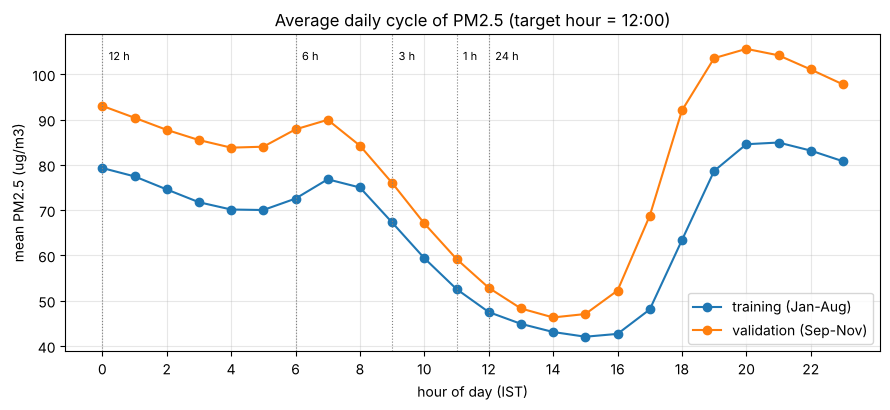

,issue hour,lead (h),mean PM2.5 at issue hour (val),mean PM2.5 at 12:00 (val),persistence bias
0,12,24,52.8,52.8,-0.5
1,0,12,93.0,52.8,40.2
2,6,6,87.8,52.8,35.0
3,9,3,76.0,52.8,23.2
4,11,1,59.2,52.8,6.4


In [48]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for label, D_ in [("training (Jan-Aug)", W.loc[:"2024-08-31"]), ("validation (Sep-Nov)", W.loc["2024-09-01":])]:
    by_hour = D_.groupby(D_.index.hour).mean().mean(axis=1)
    ax.plot(by_hour.index, by_hour.values, marker="o", label=label)
for lead, hour in [(24, 12), (12, 0), (6, 6), (3, 9), (1, 11)]:
    ax.axvline(hour, color="grey", lw=0.8, ls=":"); ax.text(hour + 0.2, ax.get_ylim()[1] * 0.97, f"{lead} h", fontsize=8, va="top")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (IST)"); ax.set_ylabel("mean PM2.5 (ug/m3)")
ax.set_title("Average daily cycle of PM2.5 (target hour = 12:00)"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

V_ = W.loc["2024-09-01":]
cycle = V_.groupby(V_.index.hour).mean().mean(axis=1)
pd.DataFrame({"issue hour": [12, 0, 6, 9, 11], "lead (h)": [24, 12, 6, 3, 1],
              "mean PM2.5 at issue hour (val)": [cycle[h] for h in [12, 0, 6, 9, 11]], "mean PM2.5 at 12:00 (val)": cycle[12],
              "persistence bias": [results.query("method == 'Persistence' and `lead (h)` == @l")["bias"].item() for l in [24, 12, 6, 3, 1]]}).round(1)

### Answers to the Part 3 questions
**Does persistence behave differently at 1 h, 24 h and in between? Why?**
Yes, and its error is not monotonic in lead time. Validation RMSE is 23.95 at 1 h, then 51.43 at 3 h, 66.82 at 6 h and 72.74 at 12 h, but it drops back to 32.75 at 24 h. The reason is the daily cycle of PM2.5 (see the daily-cycle subsection above). In the validation period the network average is about 93 µg/m³ at midnight and about 88 at 06:00, but only about 53 at noon: at night the boundary layer is shallow and pollution is trapped near the ground, while daytime heating mixes it through a deeper layer. Persistence copies the reading at the issue hour, so from 00:00 or 06:00 it carries the night-time level into a noon target and over-predicts by about 40 and 35 µg/m³ on average (the bias column). At 24 h the issue hour and the target hour are both 12:00, so the daily cycle cancels and only the genuine day-to-day change remains. That is the "dip" at 24 h. At 1 h the issue hour (11:00) is already close to the noon level, so persistence is good.

**Do the learned models also display the same behaviour?**
Mostly not, because each is refitted for its lead and learns the average night-to-noon relation. The Laplace model's RMSE is 20.58 at 1 h and then nearly flat, 27.25 to 29.08 for 3 to 24 h, and the Part 1 ridge rises from 18.95 to a maximum of 33.72 at 6 h and comes back to 29.58 at 24 h. A small dip at 24 h remains for both: from noon on day d the model has today's noon reading, the same hour as the target, while from 00:00 or 06:00 it has to infer how strongly the next morning will mix. The log-space Laplace model handles this much better than the level-space ridge (6 h: 29.08 vs 33.72), because the night-to-noon change is roughly a fixed *proportion* (noon is about 60% of the 00:00 level in the validation median), which is a constant in log space but level-dependent in µg/m³. At 1 h the ridge has the lowest RMSE of the three forecasts (18.95 vs 20.58 for the Laplace mean), but this depends on which Laplace forecast is used (see the mean-vs-median subsection above): the Laplace *median* forecast gets 19.20 RMSE and 7.50 MAE at 1 h, so it roughly ties the ridge on RMSE and clearly beats it on MAE (8.67). Across leads the median has the lower RMSE at 1, 3 and 6 h and the smeared mean at 12 and 24 h, while the median has the lower MAE at every lead. The mean forecast over-predicts at 1 h (bias +4.2 against +0.5 for ridge); with so little left to predict, a bias of a few µg/m³ is a large part of the error. We keep the smeared mean as the reported forecast because it is the one chosen in Part 2 and it is best at the 24 h lead that matters for the task.

**Which lead time would you choose for a public warning service, and what does that choice cost in accuracy?**
The 24-hour lead (issued at 12:00 on day d). A warning is only useful if people can act on it: plan outdoor activities, schools or work, and the protective steps they need, the day before. It costs surprisingly little accuracy: our model's RMSE is 28.16 at 24 h against 20.58 at 1 h (7.6 µg/m³ worse), and it is no worse than issuing at midnight or 06:00 (28.63 and 29.08), which would give less warning. A 1-hour nowcast is more accurate but leaves too little time to act; it is useful as a same-day update, not as the advisory.

## Part 4: Forecast maps vs observed maps
Station values are interpolated to the 0.05° Bihar grid (3,396 points) with inverse-distance weighting (power 2, all stations), the **same interpolation for observed values and for forecasts**, so map differences come only from the forecasts.

**Model shown:** the final Part 2 model (Laplace linear model on `log1p`, smeared mean; validation forecasts from the *Final model* subsection of Part 2), next to persistence and the Part 1 ridge.

### IDW interpolator and map helper

91 validation days; 3396 grid cells; 468 stations
Cells exactly on a station: 0


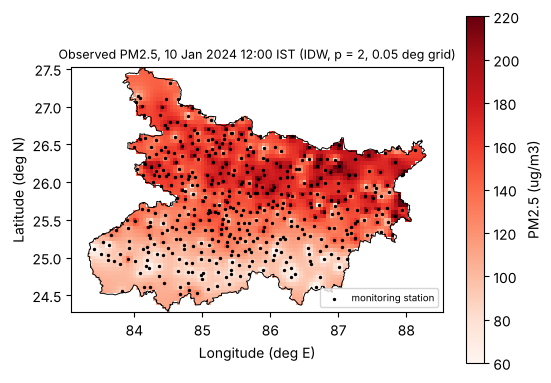

In [49]:
grid = pd.read_csv(DATA_DIR / "bihar_grid_005deg.csv")
boundary = pd.read_csv(DATA_DIR / "bihar_boundary.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
MODEL_NAME = "Laplace (Part 2)"
T_tgt = T_val + pd.Timedelta(hours=24)
dates_p4 = T_tgt.normalize()
print(len(T_tgt), "validation days;", len(grid), "grid cells;", len(stations), "stations")

gx = (grid.longitude.to_numpy() - 85.5) * 100.3
gy = (grid.latitude.to_numpy() - 25.7) * 110.6
sxy = stations[["x_km", "y_km"]].to_numpy()
Dg = np.sqrt((gx[:, None] - sxy[None, :, 0]) ** 2 + (gy[:, None] - sxy[None, :, 1]) ** 2)      # 3396 x 468, km
EPS = 1e-6
Wt = 1.0 / np.maximum(Dg, EPS) ** 2
on_station = Dg.min(axis=1) < EPS
Wt[on_station] = (Dg[on_station] < EPS).astype(float)
Wt /= Wt.sum(axis=1, keepdims=True)
def idw(V):
    # V: (..., 468) station values -> (..., 3396) grid values
    return np.asarray(V) @ Wt.T
print("Cells exactly on a station:", int(on_station.sum()))

lons = np.round((grid.longitude.to_numpy() - grid.longitude.min()) / 0.05).astype(int)
lats = np.round((grid.latitude.to_numpy() - grid.latitude.min()) / 0.05).astype(int)
lon_axis = grid.longitude.min() + 0.05 * np.arange(lons.max() + 1)
lat_axis = grid.latitude.min() + 0.05 * np.arange(lats.max() + 1)
def to_mesh(m):
    Z = np.full((len(lat_axis), len(lon_axis)), np.nan); Z[lats, lons] = m; return Z
def draw(ax, m, title, vmin, vmax, cmap="Reds"):
    h = ax.pcolormesh(lon_axis, lat_axis, to_mesh(m), cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    ax.plot(boundary.longitude, boundary.latitude, "k-", lw=0.7)
    ax.scatter(stations.longitude, stations.latitude, s=2, c="k", label="monitoring station")
    ax.set_title(title, fontsize=9); ax.set_xlabel("Longitude (deg E)"); ax.set_ylabel("Latitude (deg N)")
    ax.set_aspect(1.0 / np.cos(np.deg2rad(25.7)))
    return h

t0 = pd.Timestamp("2024-01-10 12:00")                  # the task document's Figure 1 (training period, observed only)
fig, ax = plt.subplots(figsize=(6, 4.5))
h = draw(ax, idw(W.loc[t0].to_numpy()), "Observed PM2.5, 10 Jan 2024 12:00 IST (IDW, p = 2, 0.05 deg grid)", 60, 220)
fig.colorbar(h, ax=ax, label="PM2.5 (ug/m3)"); ax.legend(loc="lower right", fontsize=7); plt.show()

In [50]:
n_days = len(T_val)
OBS = W.loc[T_tgt].to_numpy()                                           # observed at target (91 x 468)
PERS = persistence(W, T_val).reshape(n_days, N)
RIDGE = part1_ridge_predict(W, stations, T_val).reshape(n_days, N)
MODEL = np.clip(final_pred_val.reshape(n_days, N), 0, None)

def daily_metrics(pred):
    Om, Fm = idw(OBS), idw(pred)
    st = np.sqrt(((np.clip(pred, 0, None) - OBS) ** 2).mean(axis=1))                    # station RMSE per day
    mp = np.sqrt(((Fm - Om) ** 2).mean(axis=1))                                          # map RMSE per day
    pc = np.array([np.corrcoef(Fm[i], Om[i])[0, 1] for i in range(len(Om))])             # pattern correlation per day
    return pd.DataFrame({"station_rmse": st, "map_rmse": mp, "pattern_corr": pc}, index=dates_p4)

candidates = {"Persistence": PERS, "Ridge (Part 1)": RIDGE, MODEL_NAME: MODEL}
daily = {k: daily_metrics(v) for k, v in candidates.items()}
summary = pd.DataFrame({k: {"overall station RMSE": np.sqrt(((np.clip(candidates[k], 0, None) - OBS) ** 2).mean()),
                            "mean daily station RMSE": d.station_rmse.mean(), "mean daily map RMSE": d.map_rmse.mean(),
                            "mean pattern corr": d.pattern_corr.mean()} for k, d in daily.items()}).T.round(3)
assert abs(summary.loc["Persistence", "overall station RMSE"] - 32.75) < 0.01 and abs(summary.loc["Ridge (Part 1)", "overall station RMSE"] - 29.58) < 0.01
assert not any(d.isna().any().any() for d in daily.values())
model_daily = daily[MODEL_NAME]

### Three days, four panels each
One clean day (lowest network mean), one polluted day (highest network mean) and the day on which the model's station RMSE was worst. Side by side: observed map, forecast map, persistence map, and forecast − observed. Stations and the state outline are drawn on top. The three PM2.5 panels share one colour scale; the difference panel has its own symmetric scale (levels and errors are different quantities).

,date,network mean obs,model station RMSE,persistence station RMSE
clean,2024-09-15,7.890449,16.064987,27.282976
polluted,2024-11-27,174.969209,63.232641,71.668258
worst,2024-11-29,76.632521,82.314321,112.006204


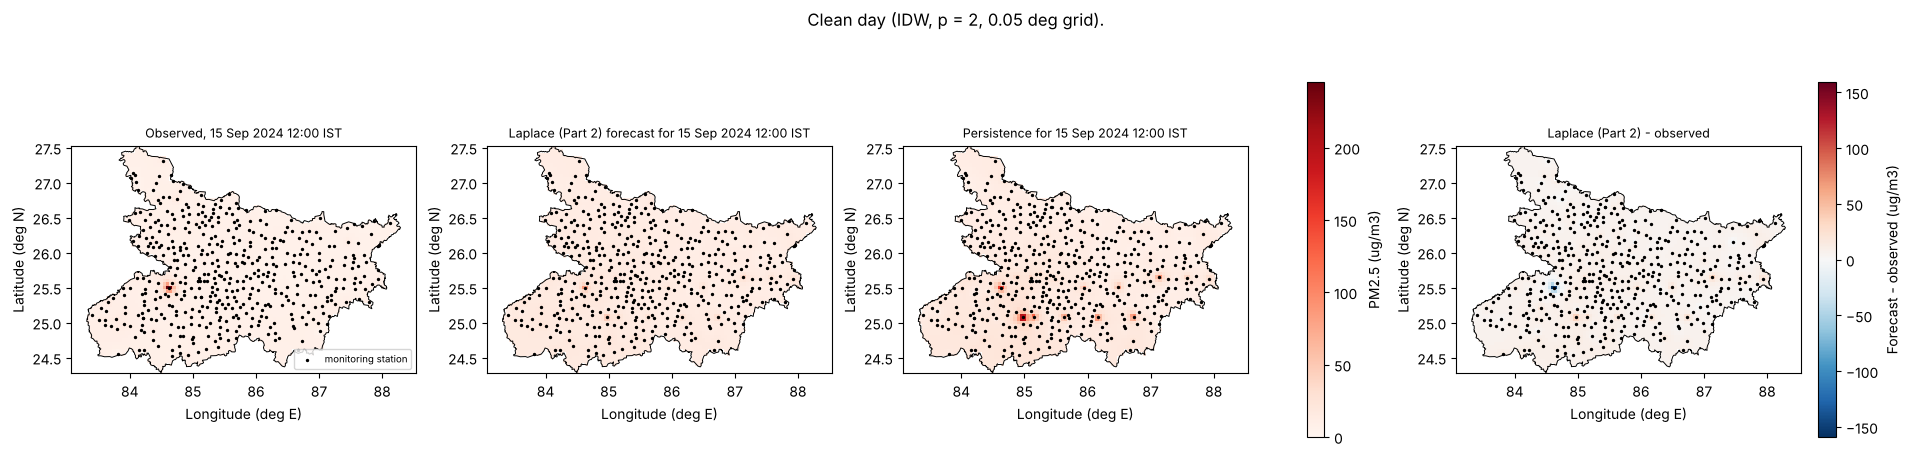

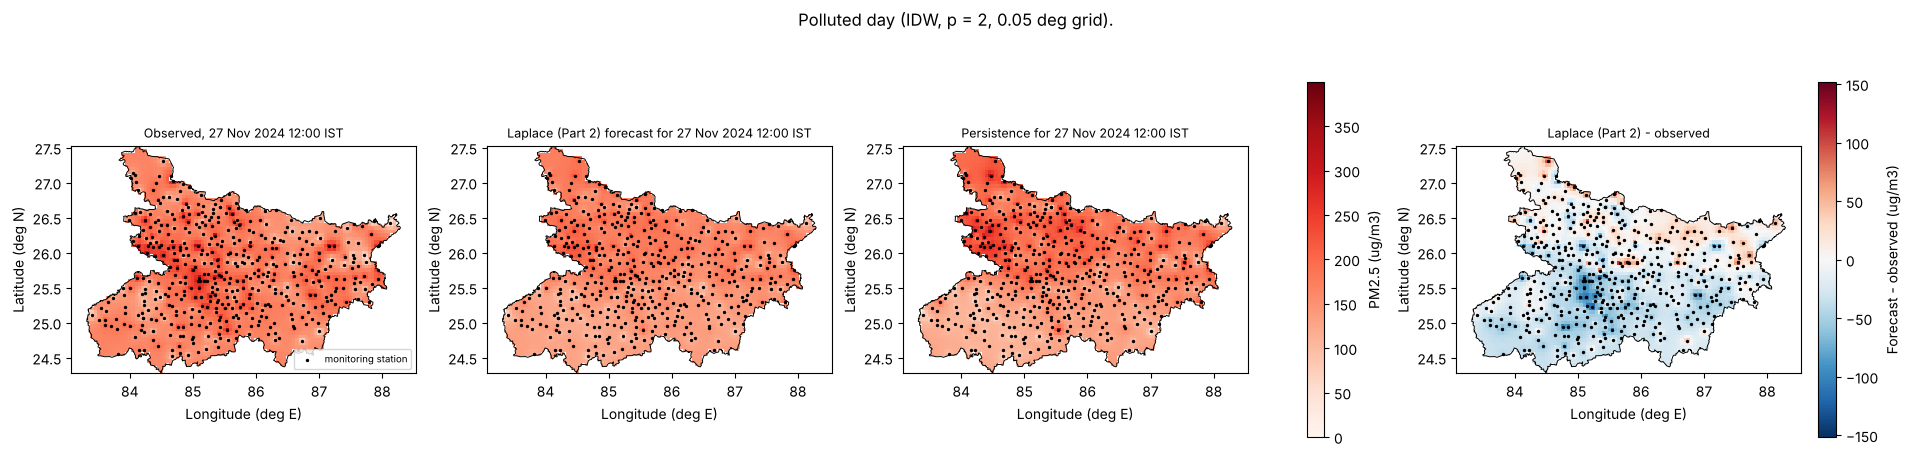

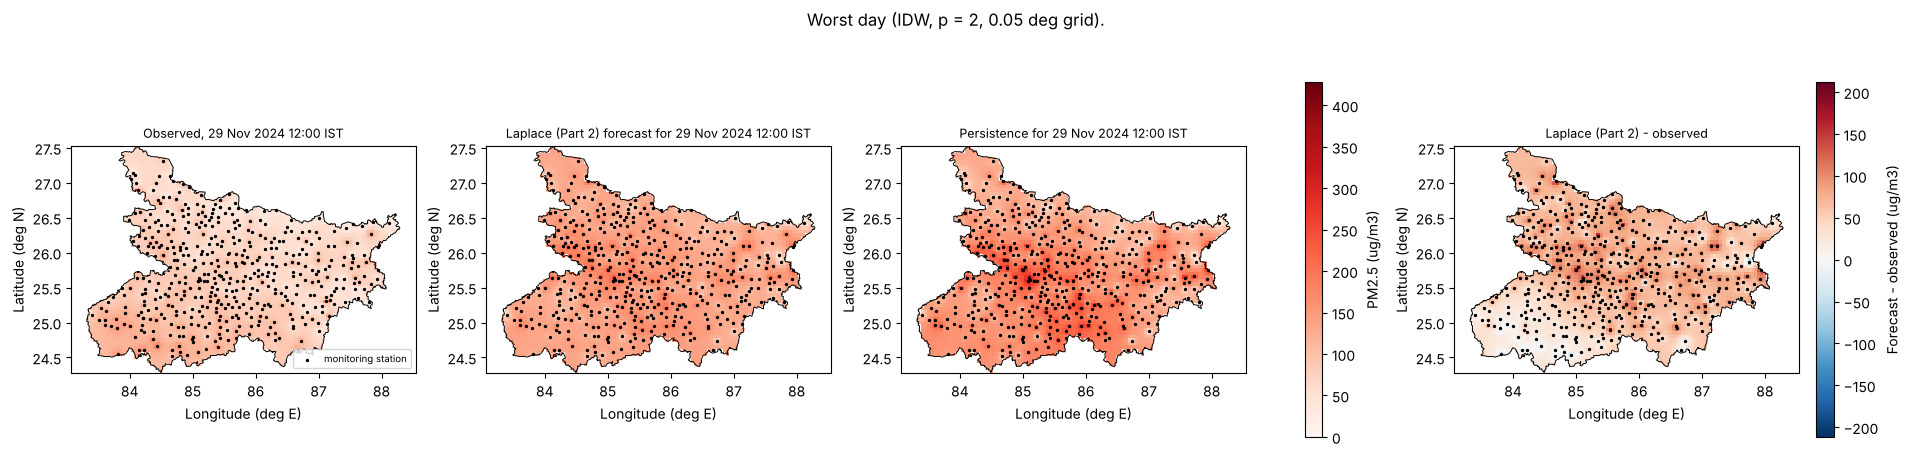

In [51]:
net_mean = pd.Series(OBS.mean(axis=1), index=dates_p4)
picks = {"clean": net_mean.idxmin(), "polluted": net_mean.idxmax(), "worst": model_daily.station_rmse.idxmax()}
display(pd.DataFrame({k: {"date": d.date(), "network mean obs": net_mean[d], "model station RMSE": model_daily.station_rmse[d],
                          "persistence station RMSE": daily["Persistence"].station_rmse[d]} for k, d in picks.items()}).T.round(2))

def plot_day(date, tag):
    i = int(np.where(dates_p4 == date)[0][0])
    O, F_, P = idw(OBS[i]), idw(MODEL[i]), idw(PERS[i])
    vmax = max(np.nanmax(O), np.nanmax(F_), np.nanmax(P)); dmax = np.nanmax(np.abs(F_ - O))
    day = f"{date:%d %b %Y} 12:00 IST"
    fig, axs = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
    draw(axs[0], O, f"Observed, {day}", 0, vmax)
    h = draw(axs[1], F_, f"{MODEL_NAME} forecast for {day}", 0, vmax)
    draw(axs[2], P, f"Persistence for {day}", 0, vmax)
    hd = draw(axs[3], F_ - O, f"{MODEL_NAME} - observed", -dmax, dmax, cmap="RdBu_r")
    fig.colorbar(h, ax=axs[:3], label="PM2.5 (ug/m3)", shrink=0.8); fig.colorbar(hd, ax=axs[3], label="Forecast - observed (ug/m3)", shrink=0.8)
    axs[0].legend(loc="lower right", fontsize=7); fig.suptitle(f"{tag.capitalize()} day (IDW, p = 2, 0.05 deg grid).")
    fig.savefig(FIG_DIR / f"part4_{tag}.png", dpi=150); plt.show()

for tag, d in picks.items():
    plot_day(d, tag)

### Map RMSE and pattern correlation for every validation day
(a) map RMSE = root mean squared grid-cell difference between the forecast and observed maps; (b) pattern correlation = correlation across grid cells between the two maps. Averages are reported next to the station RMSE.

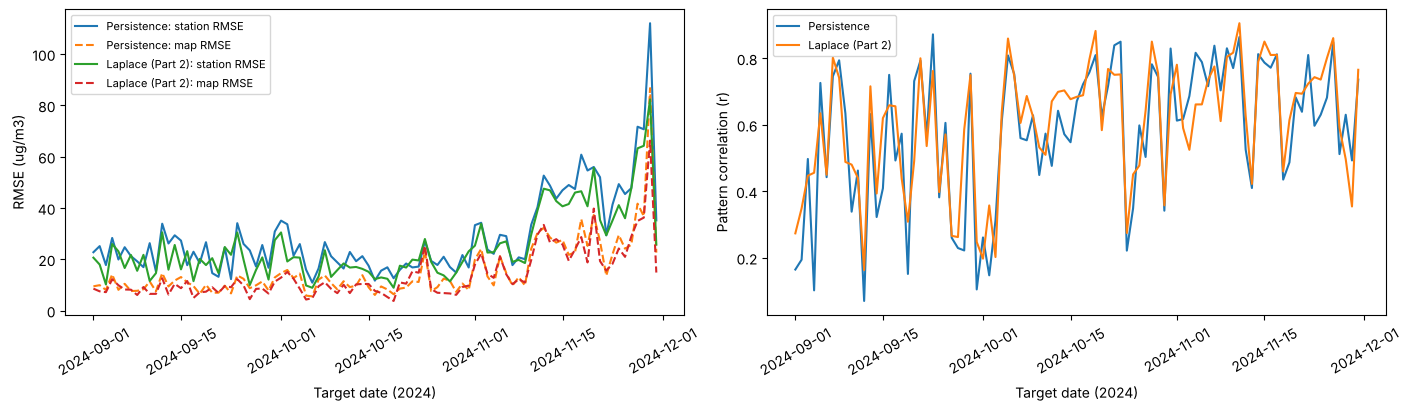

,overall station RMSE,mean daily station RMSE,mean daily map RMSE,mean pattern corr
Persistence,32.745,28.568,15.369,0.580
Ridge (Part 1),29.584,26.001,15.419,0.605
Laplace (Part 2),28.162,24.745,13.839,0.604


In [52]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for name in ["Persistence", MODEL_NAME]:
    d = daily[name]
    axs[0].plot(d.index, d.station_rmse, label=f"{name}: station RMSE"); axs[0].plot(d.index, d.map_rmse, "--", label=f"{name}: map RMSE")
    axs[1].plot(d.index, d.pattern_corr, label=name)
axs[0].set_ylabel("RMSE (ug/m3)"); axs[0].legend(fontsize=8); axs[1].set_ylabel("Pattern correlation (r)"); axs[1].legend(fontsize=8)
for a in axs: a.set_xlabel("Target date (2024)"); a.tick_params(axis="x", rotation=30)
plt.show()
summary

**Reading the table.** The Part 1 ridge improves on persistence in station RMSE (29.58 vs 32.75) but not in map RMSE (15.42 vs 15.37), and mean pattern correlation barely moves across the three forecasts (0.58 to 0.61). The learned models' gains are mostly in getting the overall *level* right at the stations, not in the spatial pattern, so map RMSE and pattern correlation should not be quoted as forecast accuracy.

### Is the observed map ground truth? Leave-one-station-out check
Remove each station in turn, interpolate its value from the other 467 with the same IDW (p = 2), and compare with what it actually measured, for every validation target. This is the error the interpolation itself makes at a place with no sensor.

In [53]:
Dss = np.sqrt(((sxy[:, None] - sxy[None]) ** 2).sum(axis=2)); np.fill_diagonal(Dss, np.inf)
W_loo = 1.0 / Dss ** 2; W_loo /= W_loo.sum(axis=1, keepdims=True)
LOO = OBS @ W_loo.T
print(f"leave-one-station-out IDW on validation targets: RMSE {np.sqrt(((LOO - OBS) ** 2).mean()):.1f} ug/m3, correlation {np.corrcoef(LOO.ravel(), OBS.ravel())[0, 1]:.2f}")
print(f"median distance to the nearest other station: {np.median(Dss.min(axis=1)):.1f} km")

leave-one-station-out IDW on validation targets: RMSE 32.9 ug/m3, correlation 0.81
median distance to the nearest other station: 9.0 km


### A real case of good pattern correlation but poor RMSE

,pattern corr,map RMSE,map bias (forecast - observed),observed map mean
2024-11-11,0.91,29.62,-25.15,102.12
2024-11-26,0.86,28.91,-10.37,160.59
2024-11-15,0.85,25.77,-19.35,115.11


median pattern corr over all days: 0.64; mean map RMSE: 13.84


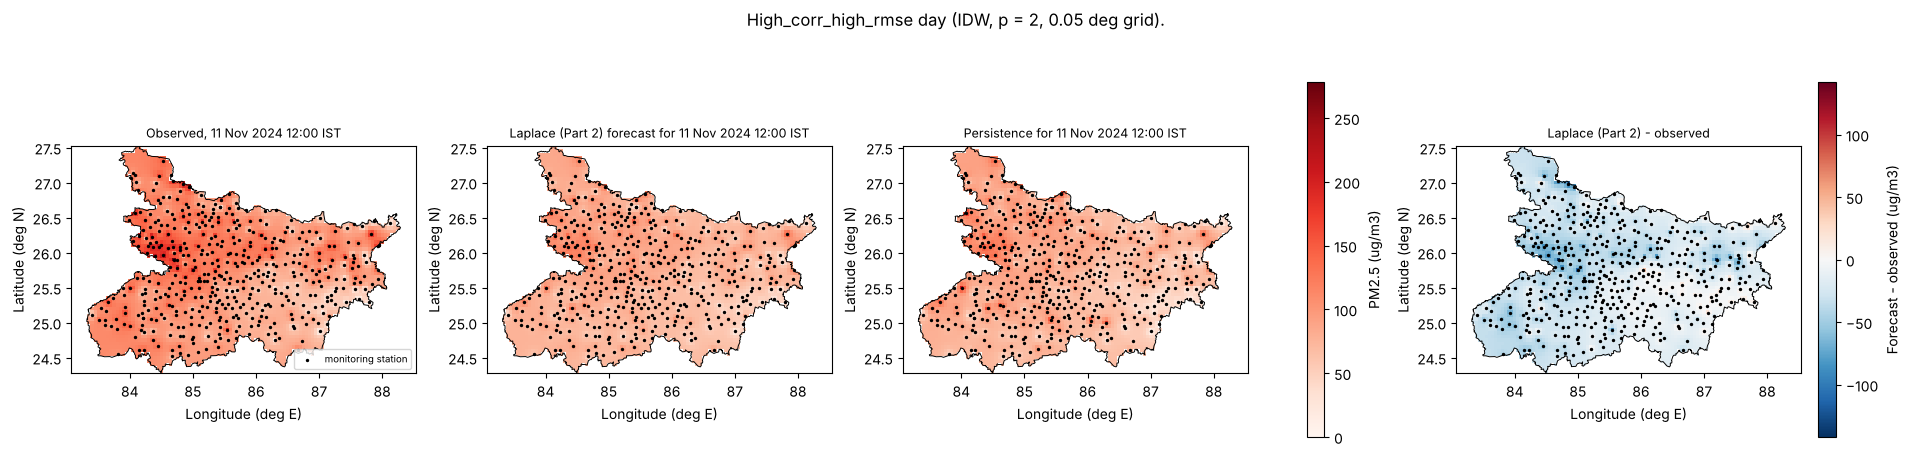

In [54]:
Mm_all, Om_all = idw(MODEL), idw(OBS)
ex = pd.DataFrame({"pattern corr": model_daily.pattern_corr, "map RMSE": model_daily.map_rmse,
                   "map bias (forecast - observed)": (Mm_all - Om_all).mean(axis=1), "observed map mean": Om_all.mean(axis=1)}, index=dates_p4)
display(ex[ex["pattern corr"] > 0.85].sort_values("map RMSE", ascending=False).head(3).round(2))
print(f"median pattern corr over all days: {ex['pattern corr'].median():.2f}; mean map RMSE: {ex['map RMSE'].mean():.2f}")
plot_day(pd.Timestamp("2024-11-11"), "high_corr_high_rmse")

### Answers to the Part 4 questions
**Which RMSE is better, map or station? Which to quote?**
For our model (Laplace, Part 2) the mean daily map RMSE is 13.84 µg/m³ against a mean daily station RMSE of 24.75 (overall station RMSE 28.16); for persistence 15.37 against 28.57 (overall 32.75). Map RMSE is about half the station RMSE: IDW is a smoothing average, so independent station-level errors partly cancel. That lower number is partly an artefact of interpolation, not better forecasting. Quote the **station RMSE** as forecast accuracy: it is checked against real readings and cannot be flattered by smoothing. Map RMSE is useful particularly for judging the spatial picture.

**In what sense is the observed map not ground truth?**
It is an IDW interpolation of 468 point sensors: between stations it is just a distance-weighted average, so it cannot represent local values that lie between sensors. The sensors themselves are low-cost and some readings were gap-filled upstream, so even the station values are not exact. Therefore the observed map is not the ground truth. We can measure how far off it is: leaving each station out and interpolating it from the other 467 gives an RMSE of 32.9 µg/m³ (correlation 0.81) on the validation targets, with the nearest other station a median 9 km away. That interpolation error is as large as the forecast errors being compared (28.2 for our model, 32.75 for persistence), so between stations the "observed" map is a weak yardstick.

**Describe a forecast that has a good pattern correlation but a poor RMSE. Which matters more for a public warning?**
A forecast that gets the spatial *shape* right but the overall *level* wrong. Our own model on 11 Nov 2024 is an example: its map has a pattern correlation of 0.91 (median over all days 0.64), but a map RMSE of 29.6 µg/m³, about twice its average of 13.8, because it under-predicted almost everywhere by about 25 µg/m³ on a day with an observed mean of 102. For a public warning the **absolute level** matters more, because health advice and alert bands are tied to concentration thresholds.

## Part 5: Final refit and submission files

### Refit on all targets up to 30 Nov and write `model.json`
Same model class, same 25 features, same hyper-parameters (`l2 = 1e-3`, smeared mean); nothing is re-tuned. Training rows: all issue days from 2 Jan to 29 Nov 12:00 (targets 3 Jan to 30 Nov) = 333 days x 468 = **155,844 rows**, i.e. the previous 113,256 rows plus the 91 validation days. 

In [55]:
T_all, _ = issue_times(24, train_end="2024-11-30 12:00")
y_all = targets(W, T_all)
assert (T_all + pd.Timedelta(hours=24)).max() <= pd.Timestamp("2024-11-30 12:00") and len(y_all) == 333 * N == 155_844
X_all, names_all, _ = extract_features(W, T_all, ctx, FINAL_GROUPS)
assert X_all.shape == (155_844, 25) and names_all == feature_names

final_model = LogLaplaceForecaster(l2=1e-3, mode="mean").fit(X_all, y_all)       # scaler, IRLS fit and smearing: these rows only
lap_ = final_model.model_
model_json = dict(feature_names=names_all, groups=list(FINAL_GROUPS), l2=1e-3,
                  x_mean=lap_.scaler_.mean_.tolist(), x_scale=lap_.scaler_.scale_.tolist(), coef=lap_.coef_.tolist(),
                  smearing=float(final_model.smearing_), max_pm25=MAX_PM25, trained_through_target="2024-11-30 12:00",
                  n_train_rows=int(len(y_all)), n_issue_days=int(len(T_all)))
OUT_DIR.mkdir(exist_ok=True)
json.dump(model_json, open(OUT_DIR / "model.json", "w"), indent=1)

coef_shift = np.max(np.abs(lap_.coef_ - laplace.model_.coef_))
print(f"saved {OUT_DIR / 'model.json'}: {len(y_all):,} rows ({len(T_all)} issue days x {N}), smearing = {final_model.smearing_:.4f}")
print(f"largest change in a standardised coefficient vs the Aug-fit model used in Part 2: {coef_shift:.3f} (smearing {laplace.smearing_:.4f} -> {final_model.smearing_:.4f})")

saved submission/model.json: 155,844 rows (333 issue days x 468), smearing = 1.1119
largest change in a standardised coefficient vs the Aug-fit model used in Part 2: 0.070 (smearing 1.1192 -> 1.1119)


### Write `forecast.py` and copy `bihar_stations.csv`
`forecast.py` rebuilds the 25 features for a **single** issue time from the last 200 hourly rows of `history` (the longest window is the 168 h mean) with the same formulas as the *Features* subsection of Part 2, standardises them with the stored mean and scale, and applies `exp(mu) × smearing − 1`, clipped to [0, 500]. The file follows the course template (`MODEL` loaded once at import, then `forecast(history, issue_time)`); if fewer than 168 hours of history are given it falls back to persistence, which does not happen in the grader's calls. The checks in the *Checks* subsection below verify that it reproduces the notebook's batch features exactly.

In [56]:
FORECAST_SRC = r'''"""Part 5: next-day (24 h) noon PM2.5 forecast for the 468 Bihar stations.

Linear model on log1p(PM2.5), fitted by least absolute deviations (Laplace likelihood), forecast = smeared mean
exp(mu) * smearing - 1. Fitted on all targets 3 Jan - 30 Nov 2024 (Part 5 of the project notebook); nothing is refitted inside forecast().
"""
from pathlib import Path
import json

import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent
N = 468

# Load fitted objects once, at import time.
MODEL = json.load(open(HERE / "model.json"))
MEAN, SCALE, COEF = np.array(MODEL["x_mean"]), np.array(MODEL["x_scale"]), np.array(MODEL["coef"])
SMEARING, MAX_PM25 = MODEL["smearing"], MODEL["max_pm25"]
STATIONS = pd.read_csv(HERE / "bihar_stations.csv", dtype={"sensor_id": str}).set_index("sensor_id")

# Neighbour-averaging matrices: row s has 1/k on the k nearest OTHER stations of s (km conversion from the spec).
xy = np.column_stack([(STATIONS.longitude - 85.5) * 100.3, (STATIONS.latitude - 25.7) * 110.6])
dist = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(axis=2))
np.fill_diagonal(dist, np.inf)
nearest = np.argsort(dist, axis=1, kind="stable")
A = {k: np.zeros((N, N)) for k in (10, 75)}
for k in A:
    A[k][np.arange(N)[:, None], nearest[:, :k]] = 1.0 / k


def forecast(history: pd.DataFrame, issue_time: pd.Timestamp) -> pd.Series:
    """history: wide hourly table (DatetimeIndex 'timestamp', one string column per sensor_id),
    every hour from 1 Jan 2024 00:00 up to and including issue_time.
    issue_time: 12:00 on some day (IST).
    Returns predicted PM2.5 for issue_time + 24 h, indexed by sensor_id (all 468 stations)."""
    window = history.loc[issue_time - pd.Timedelta(hours=199): issue_time]   # last 200 hours (longest window: 168 h)
    V = window.to_numpy(dtype=float)                                          # (200, 468); last row = issue time
    if len(V) < 168:                                                          # too little history for the 7-day mean: persistence
        return pd.Series(np.clip(V[-1], 0, None), index=history.columns, name="pm25_forecast")
    i = len(V) - 1
    now, mean24, mean6 = V[i], V[i - 23:].mean(axis=0), V[i - 5:].mean(axis=0)

    # own: log readings at lags 0,1,2,3,6,12,18,23 h and mean, min, max, std of the last 24 h
    lags = np.log1p(V[i - 23:][::-1])                                         # row k = reading at t - k h
    own = np.column_stack([lags[[0, 1, 2, 3, 6, 12, 18, 23]].T, lags.mean(0), lags.min(0), lags.max(0), lags.std(0)])
    prevday = np.log1p(V[i - 24])[:, None]                                    # same hour yesterday

    # nbr: 10 and 75 nearest stations (now and 24 h mean), own reading minus its 10-neighbour mean
    n10, n10_24, n75, n75_24 = A[10] @ now, A[10] @ mean24, A[75] @ now, A[75] @ mean24
    nbr = np.column_stack([np.log1p(n10), np.log1p(n10_24), np.log1p(n75), np.log1p(n75_24),
                           np.log1p(now) - np.log1p(n10)])

    # network: statewide level now, its 24 h change, spread across stations
    log_net = np.log1p(now.mean())
    net = np.tile([log_net, log_net - np.log1p(V[i - 24].mean()), np.log1p(now).std()], (N, 1))

    # trend: 18 h change, last 6 h vs previous 6 h, last 24 h vs previous 24 h
    trend = np.column_stack([np.log1p(now) - np.log1p(V[i - 17]),
                             np.log1p(mean6) - np.log1p(V[i - 11:i - 5].mean(axis=0)),
                             np.log1p(mean24) - np.log1p(V[i - 47:i - 23].mean(axis=0))])

    long = np.log1p(V[i - 167:].mean(axis=0))[:, None]                        # 7-day mean

    X = np.hstack([own, prevday, nbr, net, trend, long])                      # (468, 25)
    mu = COEF[0] + ((X - MEAN) / SCALE) @ COEF[1:]                            # log1p scale
    prediction = np.exp(mu) * SMEARING - 1.0                                  # smeared-mean back-transform

    return pd.Series(np.clip(prediction, 0, MAX_PM25), index=history.columns, name="pm25_forecast")
'''

(OUT_DIR / "forecast.py").write_text(FORECAST_SRC)
shutil.copy(DATA_DIR / "bihar_stations.csv", OUT_DIR / "bihar_stations.csv")
print(sorted(p.name for p in OUT_DIR.iterdir()))

['bihar_stations.csv', 'forecast.py', 'model.json']


### Checks on the submission files
1. **Same path as the grader, honest numbers.** A copy of the submission folder with the model fitted on **training rows only** (the Part 2 model) is called through `forecast()` for all 91 validation issue times, with `history` cut at the issue time. Its RMSE must equal the notebook's 28.16 and its forecasts must match the batch forecasts to rounding error. This tests the single-issue-time feature code, the JSON model and the back-transform end to end.
2. **No leakage.** Scrambling every history row *after* the issue time must not change the forecast (tolerance 1e-9); as a control, scrambling the last 6 hours *before* the issue time must change it.
3. **Fallback.** A history table with fewer than 168 hours (here 10) returns the persistence forecast.



In [57]:
import importlib.util, hashlib, os

def load_forecast_module(folder, name):
    spec = importlib.util.spec_from_file_location(name, Path(folder) / "forecast.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    return mod

# --- 1. validation-protocol copy of the submission (model fitted on training rows only)
VAL_DIR = Path("_submission_val_check"); VAL_DIR.mkdir(exist_ok=True)
shutil.copy(OUT_DIR / "forecast.py", VAL_DIR / "forecast.py"); shutil.copy(OUT_DIR / "bihar_stations.csv", VAL_DIR / "bihar_stations.csv")
val_json = dict(model_json, x_mean=laplace.model_.scaler_.mean_.tolist(), x_scale=laplace.model_.scaler_.scale_.tolist(),
                coef=laplace.model_.coef_.tolist(), smearing=float(laplace.smearing_), trained_through_target="2024-08-31 12:00",
                n_train_rows=int(len(y_train)), n_issue_days=int(len(T_train)))
json.dump(val_json, open(VAL_DIR / "model.json", "w"))
fval = load_forecast_module(VAL_DIR, "forecast_val_check")

t0 = time.perf_counter()
out_val = np.vstack([fval.forecast(W.loc[:t].copy(), t).to_numpy() for t in T_val])
per_call = (time.perf_counter() - t0) / len(T_val)
batch = final_pred_val.reshape(len(T_val), N)
rmse_fc = float(np.sqrt(np.mean((out_val.ravel() - y_val) ** 2)))
print(f"forecast.py over the 91 validation issue times: RMSE {rmse_fc:.4f} (notebook batch: {rmse_clipped(final_pred_val, y_val):.4f}), "
      f"max |difference| to batch forecasts {np.abs(out_val - batch).max():.2e} ug/m3, {per_call * 1000:.0f} ms per call")
assert np.abs(out_val - batch).max() < 1e-6 and abs(rmse_fc - rmse_clipped(final_pred_val, y_val)) < 1e-6

# --- 2. leakage with a control
t = T_val[40]; hist = W.loc[:t].copy(); base = fval.forecast(hist, t).to_numpy()
future = W.loc[:t + pd.Timedelta(days=3)].copy(); rows_after = future.index > t
rng_l = np.random.default_rng(SEED); future.loc[rows_after] = rng_l.uniform(0, 500, future.loc[rows_after].shape)
assert np.abs(fval.forecast(future, t).to_numpy() - base).max() < 1e-9, "forecast uses rows after the issue time"
control = hist.copy(); control.iloc[-6:] = rng_l.uniform(0, 500, control.iloc[-6:].shape)
changed = np.abs(fval.forecast(control, t).to_numpy() - base).max()
assert changed > 1.0, "control failed: scrambling the last 6 h should change the forecast"
print(f"leakage test passed (future rows scrambled: no change; control, last 6 h scrambled: forecasts move by up to {changed:.0f} ug/m3)")

# --- 3. fallback with too little history
short_t = pd.Timestamp("2024-01-01 09:00"); short = fval.forecast(W.loc[:short_t].copy(), short_t)
assert np.allclose(short.to_numpy(), W.loc[short_t].to_numpy()), "< 168 h of history should fall back to persistence"
print("fallback test passed (< 168 h of history -> persistence)")


forecast.py over the 91 validation issue times: RMSE 28.1625 (notebook batch: 28.1625), max |difference| to batch forecasts 6.79e-12 ug/m3, 16 ms per call
leakage test passed (future rows scrambled: no change; control, last 6 h scrambled: forecasts move by up to 232 ug/m3)
fallback test passed (< 168 h of history -> persistence)
